# 3D-08 — Rendu analytique contre radiance field : quand la scène se laisse écrire

[← Flow matching voxel joint (3D-07)](3D-07-Flow-Matching-Voxel-Joint-Python.ipynb) | [← Annexe spark-physics (3D-06)](3D-06-Spark-Interactive-Demo.md) | [← Série GenAI/3D](README.md)

> **Ce que fait ce notebook** : les carnets précédents **apprennent** la scène — un MLP (3D-01, 3D-02), puis des gaussiennes optimisées (3D-03 à 3D-05). Celui-ci prend le chemin inverse. La scène « Saturne » est ici **déjà connue sous forme close** : deux primitives, une densité constante par morceaux, une couleur écrite. On peut donc la rendre **sans rien apprendre** — intersections exactes, profondeur optique intégrable, et *culling* par une relation d'incidence empruntée à la géométrie des spineurs. La question que ce carnet mesure : **à qualité déclarée égale, combien de temps chaque représentation demande-t-elle, et où la forme close casse-t-elle ?**

Le carnet a deux versants. Le premier est **mathématique** : la chaîne `point 3D → matrice hermitienne X^{AA'} → spineur → relation d'incidence de Penrose`, avec des vérifications numériques, et le pont SU(2)/SO(3) (double revêtement) qui relie cette géométrie à la série [`Physique/Jauge`](../../Physique/Jauge/) — en particulier Jauge-02 (invariance U(1)/SU(2)). Le second est **mesuré** : trois représentations de la même scène (forme close exacte, marche volumique échantillonnée, réseau appris) rendues sur le même matériel, comparées à PSNR égal, avec le temps chronométré et les compteurs de travail effectué.

**Prérequis** : [3D-01](3D-01-NeRF-Depuis-Zero-Python.ipynb) (rendu volumique, compositing alpha, encodage positionnel) et [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) (la scène « Saturne », les deux représentations).

*Note d'exécution* : déterministe (seed 42), **CPU uniquement** — les deux termes de chaque comparaison tournent dans le même processus, sur le même CPU, ce qui est la forme la plus stricte de l'égalité de matériel. Aucun GPU n'est requis ; compter 6 à 9 minutes, dominées par l'entraînement du réseau et les deux récupérations de pose.

## Source, licence et réserves

Ce carnet **re-dérive** — il n'installe ni n'importe — les idées de [`isopidi-stack/twistor-render-core`](https://github.com/isopidi-stack/twistor-render-core), moteur de rendu expérimental fondé sur la théorie des twisteurs de Penrose (CP³) et les 2-spineurs complexes.

> MIT License
>
> Copyright (c) 2026 Ivan (isopidi-stack)
>
> Permission is hereby granted, free of charge, to any person obtaining a copy of this software and associated documentation files (the "Software"), to deal in the Software without restriction, including without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell copies of the Software, and to permit persons to whom the Software is furnished to do so, subject to the following conditions:
>
> The above copyright notice and this permission notice shall be included in all copies or substantial portions of the Software.
>
> THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.

Cinq réserves de source, qui gouvernent la lecture de tout ce qui suit :

1. **Pose à cinq paramètres, pas six.** Le README de la source annonce « 6-DoF (x, y, z, yaw, pitch) », ce qui fait cinq. Le sixième degré n'est pas une rotation : c'est un **zoom** (la focale). Le carnet nomme donc les choses ainsi : position (3) + yaw + pitch = 5 paramètres optimisés, focale = zoom non optimisé.
2. **La nullité est forcée, pas dérivée.** `points_to_hermitian` assigne `t = sqrt(x²+y²+z²)` à un point 3D au lieu de lire la nullité d'une métrique de Lorentz 4D. C'est un **artefact de rendu**, pas un modèle physique. La section 2 en mesure la conséquence exacte, chiffrée — et propose le relèvement corrigé qui rend le test de *culling* exact.
3. **Les benchmarks de la source ne sont pas transposables.** Les accélérations annoncées (24-68×) sont des auto-mesures sur GPU Intel XPU ; il n'y a **aucun GPU Intel dans la flotte**. Aucun chiffre absolu de la source n'est repris ici. Ce qui se transpose est le **protocole** : comparer deux termes **à matériel constant**, sur la même scène, au même jeu de candidats. C'est ce protocole que la section 5 applique.
4. **Les démos de la source ne sont pas probantes physiquement** (lensing, morphing) : visuellement attractives, sans validation quantitative. Rien n'en est repris.
5. **Aucune dépendance au package.** Le code utile est re-dérivé ici, la source MIT est citée avec sa notice, et **aucun chiffre de la source n'est repris sans ré-exécution locale**.

In [1]:
import json, math, time
import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

MATERIEL = {
    "torch": torch.__version__,
    "device": "cpu",
    "threads": torch.get_num_threads(),
    "python": ".".join(str(v) for v in __import__("sys").version_info[:3]),
}
print("Materiel commun aux DEUX termes de chaque comparaison :", json.dumps(MATERIEL))
print("Aucun GPU : les deux termes tournent dans le meme processus, sur le meme CPU, sur les memes rayons.")

Materiel commun aux DEUX termes de chaque comparaison : {"torch": "2.13.0+cu126", "device": "cpu", "threads": 14, "python": "3.13.16"}
Aucun GPU : les deux termes tournent dans le meme processus, sur le meme CPU, sur les memes rayons.


## 1. Deux façons de connaître une scène

Une image est une intégrale. Rendre, c'est estimer

$$C(\mathbf{o}, \mathbf{d}) = \int_{t_{\text{near}}}^{t_{\text{far}}} T(t)\,\sigma(\mathbf{o}+t\mathbf{d})\,\mathbf{c}(\mathbf{o}+t\mathbf{d})\,dt, \qquad T(t) = \exp\!\left(-\int_{t_{\text{near}}}^{t}\sigma\,ds\right),$$

et la seule question qui distingue les représentations est **ce qu'elles savent de $\sigma$ et de $\mathbf{c}$** :

| | Forme close (ce carnet) | Radiance field appris (3D-01) | Splats optimisés (3D-03) |
|---|---|---|---|
| Ce qui est stocké | l'expression de $\sigma$ et $\mathbf{c}$ | les poids d'un MLP | les attributs d'un nuage de gaussiennes |
| Ce qui est calculé au rendu | une intégrale **résolue** | $N$ évaluations de réseau par rayon | projection, tri, mélange |
| Coût de la représentation | rédaction humaine (non mesurée ici) | entraînement | entraînement |
| Coût du rendu | géométrie exacte | $N \times$ MLP | primitives couvrantes |
| Ce qui casse | une scène non écrite | les hautes fréquences, les poses | la couverture, l'ordre |

Le point de comparaison honnête n'est donc pas « rapide contre lent », c'est : **à qualité égale, quel travail faut-il fournir ?** Pour la forme close, ce travail est de *rédiger* la scène — un coût humain que ce carnet ne mesure pas et déclare hors champ. Pour le réseau, c'est de l'*optimiser* — un coût machine que l'on mesure.

### Le protocole, déclaré avant de mesurer

Les exigences du protocole sont posées ici, avant tout chiffre, et chacune sera établie par une mesure :

| Exigence | Comment elle est établie | Où |
|---|---|---|
| **Même scène** | mêmes fonctions `densite_analytique` / `couleur_analytique`, mêmes trois poses, même résolution 80×80, même `near`/`far`/focale | §1.1 |
| **Même matériel** | un seul processus, un seul CPU, aucun transfert d'appareil ; les deux termes sont rendus par le même code de rayons | cellule suivante |
| **Parité de qualité** | les deux termes sont évalués contre **la même référence** (la marche volumique à 64 échantillons) ; un PSNR cible commun est **mesuré**, puis le temps de chacun est relevé **à ce PSNR** | §5 |
| **Équivalence du culling** | le terme analytique est cullé sur 13 primitives candidates **déclarées** ; le terme appris n'a aucune structure de primitives et est donc déclaré **sans culling** — il ne reçoit aucun crédit d'un avantage qu'il n'a pas | §3, §5 |

Une asymétrie assumée, et elle est le sujet du carnet : la forme close reçoit sa scène gratuitement (quelqu'un l'a écrite), le réseau doit la découvrir. La comparaison chiffre le prix de cette découverte ; elle ne prétend pas que l'écriture soit gratuite.

### 1.1 La scène, telle qu'elle est écrite

La scène est reprise **à l'identique** de [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) (elle-même reprise compacte de [3D-01](3D-01-NeRF-Depuis-Zero-Python.ipynb)) : une sphère pleine de rayon 0,55 centrée à l'origine, et un anneau de rayons 0,85 à 1,55, d'épaisseur 0,05, incliné de 25° autour de l'axe $x$. Les densités sont constantes par morceaux (8 dans la sphère, 6 dans l'anneau) et la couleur est une fonction écrite de la position.

Une différence de rendu avec 3D-03, déclarée : **les rayons sont ici normalisés** ($\lVert \mathbf{d}\rVert = 1$). La marche volumique de 3D-01/3D-03 laissait les directions non normalisées tout en avançant d'un pas constant, ce qui sous-estime la profondeur optique loin du centre de l'image (d'un facteur $\lVert\mathbf{d}\rVert$, jusqu'à 1,18 au coin). La correction ne change pas la scène : elle rend le pas de la marche égal à une longueur, et donc la profondeur optique exacte. Les deux termes de la comparaison partagent cette convention.

La « référence » de tout le carnet est cette marche volumique à 64 échantillons : c'est ce que le NeRF de 3D-01 s'épuisait à approcher, et c'est la cible commune.

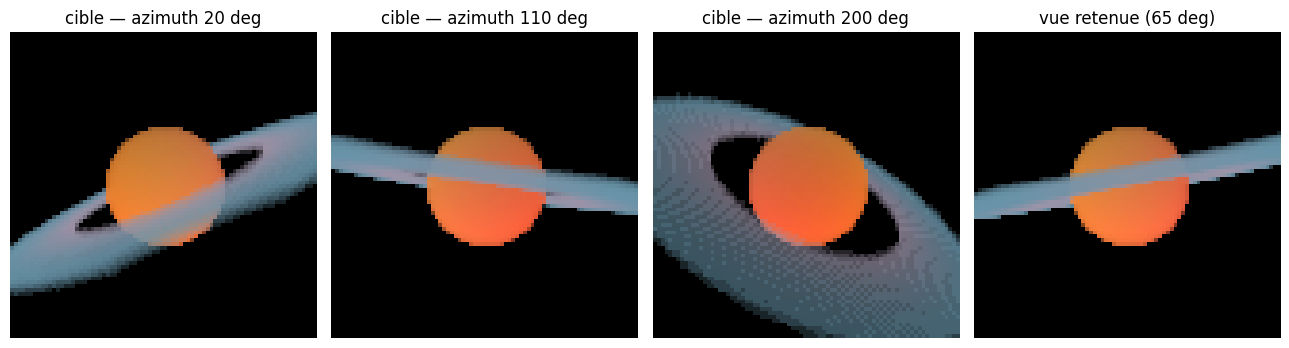

Reference : 4 vues x 64 echantillons x 6400 rayons en 0.12 s


In [2]:
# Scene « Saturne » — reprise a l'identique de 3D-03 (elle-meme reprise compacte de 3D-01).
INCLINAISON = math.radians(25.0)
H_ANNEAU = 0.05            # demi-epaisseur du disque
R_MIN, R_MAX = 0.85, 1.55  # rayons interieur / exterieur de l'anneau
RAYON_SPHERE = 0.55
SIGMA_SPHERE, SIGMA_ANNEAU = 8.0, 6.0
NORMALE_ANNEAU = torch.tensor([0.0, -math.sin(INCLINAISON), math.cos(INCLINAISON)])

def densite_analytique(p):
    # p : (..., 3). Densite sigma (...,) : sphere pleine + anneau plat incline.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2)
    d_sphere = torch.where(x**2 + y**2 + z**2 < RAYON_SPHERE**2, SIGMA_SPHERE * torch.ones_like(x), torch.zeros_like(x))
    zp = z * math.cos(INCLINAISON) - y * math.sin(INCLINAISON)
    dans_anneau = (r_axial > R_MIN) & (r_axial < R_MAX) & (zp.abs() < H_ANNEAU)
    d_anneau = torch.where(dans_anneau, SIGMA_ANNEAU * torch.ones_like(x), torch.zeros_like(x))
    return torch.clamp(d_sphere + d_anneau, max=10.0)

def couleur_analytique(p):
    # Couleur diffuse : coeur chaud, anneau gris-bleute.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2 + 1e-9)
    c_sphere = torch.stack([0.92 - 0.35 * z, 0.45 + 0.15 * x, 0.22 + 0.10 * y], dim=-1)
    c_anneau = torch.stack([0.55 + 0.15 * torch.sin(3 * r_axial), torch.full_like(x, 0.58), torch.full_like(x, 0.66)], dim=-1)
    dans_anneau = (r_axial > R_MIN) & (r_axial < R_MAX)
    return torch.where(dans_anneau.unsqueeze(-1), c_anneau, c_sphere).clamp(0, 1)

def pose_spherique(theta, r=3.2, phi=math.radians(70)):
    # Pose c2w (look-at origine) sur l'orbite, meme esprit que 3D-01.
    ct, st, cp, sp = math.cos(theta), math.sin(theta), math.cos(phi), math.sin(phi)
    return np.array([
        [-st, -ct * cp, ct * sp, r * ct * sp],
        [ ct, -st * cp, st * sp, r * st * sp],
        [0.0,       sp,      cp,      r * cp],
        [0.0,      0.0,     0.0,        1.0],
    ], dtype=np.float32)

def rayons(c2w, H, W, focal):
    """Rayons NORMALISES (|d| = 1) : le parametre t est une longueur. (H*W, 3) chacun."""
    c2w = torch.as_tensor(c2w)
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    dirs = torch.stack([(ii - W / 2) / focal, -(jj - H / 2) / focal, -torch.ones_like(ii)], dim=-1)
    d = dirs @ c2w[:3, :3].T
    d = d / torch.linalg.norm(d, dim=-1, keepdim=True)
    o = c2w[:3, -1].expand(d.shape)
    return o.reshape(-1, 3), d.reshape(-1, 3)

def rendu_volumique_analytique(theta, H=80, W=80, N=64, near=1.8, far=4.8, focal=90.0):
    # Marche volumique de la densite analytique : c'est la REFERENCE commune du carnet.
    o, d = rayons(pose_spherique(theta), H, W, focal)
    # Echantillonnage au MILIEU de chaque cellule : la regle des points milieux converge en O(1/N^2),
    # la regle des extremites (linspace) en O(1/N) et biaise tau d'un demi-pas.
    ts = near + (far - near) * (torch.arange(N, dtype=torch.float32) + 0.5) / N
    pts = o.unsqueeze(1) + d.unsqueeze(1) * ts.view(1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_analytique(pts)
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    w = alpha * torch.cumprod(torch.cat([torch.ones_like(alpha[:, :1]), 1 - alpha + 1e-10], dim=-1)[:, :-1], dim=-1)
    return torch.sum(w.unsqueeze(-1) * rgb, dim=1).clamp(0, 1)

ANGLES_CIBLES = [math.radians(a) for a in (20, 110, 200)]
ANGLE_RETENU = math.radians(65)   # jamais montre au reseau : sert a la recuperation de pose (section 7)

t0 = time.perf_counter()
vues_cibles = torch.stack([rendu_volumique_analytique(t) for t in ANGLES_CIBLES])
vue_retenue = rendu_volumique_analytique(ANGLE_RETENU)
duree_reference = time.perf_counter() - t0

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, img, a in zip(axes[:3], vues_cibles, (20, 110, 200)):
    ax.imshow(img.reshape(80, 80, 3).numpy()); ax.set_title(f"cible — azimuth {a} deg"); ax.axis('off')
axes[3].imshow(vue_retenue.reshape(80, 80, 3).numpy()); axes[3].set_title("vue retenue (65 deg)"); axes[3].axis('off')
plt.tight_layout(); plt.show()

print(f"Reference : 4 vues x 64 echantillons x 6400 rayons en {duree_reference:.2f} s")

### Lecture du résultat

Quatre rendus de référence. Les trois premiers sont les **vues d'entraînement** : tout ce que les termes appris auront le droit de voir. Le quatrième (65°) ne sera **jamais** montré au réseau — il sert de cible à la récupération de pose de la section 7, où l'on demande aux deux représentations de retrouver une caméra qu'elles n'ont pas vue.

Le chronomètre de la référence est déjà une information : quatre vues à 64 échantillons coûtent le même ordre de grandeur que ce que le réseau devra payer en quelques itérations d'entraînement. C'est la limitation n°5 mesurée en 3D-02 — le coût du rendu par rayon — et c'est précisément ce que la forme close attaque.

## 2. La chaîne projective : point → X^{AA'} → spineur → incidence

La scène ci-dessus est écrite en coordonnées cartésiennes. La géométrie des twisteurs en propose une autre lecture, où un **rayon lumineux** n'est pas une demi-droite mais une **droite d'un espace de Minkowski complexifié**, et où appartenir à cette droite est une **équation linéaire**.

Le pont est l'application de Pauli. À un quadrivecteur $(t, x, y, z)$ on associe la matrice hermitienne

$$X^{AA'} = t\,\mathbb{1} + x\,\sigma_1 + y\,\sigma_2 + z\,\sigma_3 = \begin{pmatrix} t+z & x-iy \\ x+iy & t-z \end{pmatrix}, \qquad \det X = t^2 - \lVert \mathbf{x}\rVert^2 .$$

La nullité de $X$ ($\det X = 0$) *est* l'appartenance au cône de lumière. Un rayon est alors un couple de spineurs $Z = (\omega^A, \pi_{A'})$, et la **relation d'incidence de Penrose** dit qu'un point $X$ est sur le rayon si et seulement si

$$\omega^A = i\, X^{AA'}\pi_{A'}.$$

Deux remarques de lecture, qui sont des mesures et non des commentaires. D'abord, l'application implémentée par la source **n'est pas** celle ci-dessus : `points_to_hermitian` force $t = \sqrt{x^2+y^2+z^2}$ pour tout point 3D, ce qui rend $X$ nul par construction. C'est la réserve 2. Ensuite, cette nullité forcée n'est pas un détail cosmétique : la section 2.2 chiffre exactement ce qu'elle coûte, et la section 3 montre comment un **relèvement adapté au rayon** rend le test d'incidence exact.

Convention d'indices retenue (celle de la source, pour que la comparaison soit possible) : $X_{01} = x - iy$, $X_{10} = x + iy$, et la contraction $X^{AA'}\pi_{A'}$ est implémentée comme le produit matrice-vecteur $X\,\overline{\pi}$.

In [3]:
# Inspiré de isopidi-stack/twistor-render-core v0.6.0 (MIT, Copyright (c) 2026 Ivan (isopidi-stack)).
# Notice MIT complète en tête de carnet, section « Source, licence et réserves ». Code re-dérivé, package non importé.

def point_vers_hermitienne(p, t=None):
    """p : (..., 3) -> X^{AA'} (..., 2, 2) complex64.
    t=None force t = |p| (nullite, cf reserve 2) ; t scalaire ou tenseur leve le point sur l'hyperplan t = cste."""
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    if t is None:
        t = torch.sqrt(x * x + y * y + z * z + 1e-12)
    else:
        t = t * torch.ones_like(x)
    zero = torch.zeros_like(x)
    ligne0 = torch.stack([torch.complex(t + z, zero), torch.complex(x, -y)], dim=-1)
    ligne1 = torch.stack([torch.complex(x, y), torch.complex(t - z, zero)], dim=-1)
    return torch.stack([ligne0, ligne1], dim=-2)

def hermitienne_vers_point(X):
    """Inverse de point_vers_hermitienne : renvoie (t, x, y, z)."""
    t = 0.5 * (X[..., 0, 0].real + X[..., 1, 1].real)
    z = 0.5 * (X[..., 0, 0].real - X[..., 1, 1].real)
    return torch.stack([t, X[..., 1, 0].real, X[..., 1, 0].imag, z], dim=-1)

# Verification 1 : la nullite sous deux relevements.
echantillon = torch.tensor([[0.3, -0.2, 0.4], [0.0, 0.0, 0.55], [0.9, 0.4, -0.2], [3.2, 0.0, 0.0]])
det_force = torch.linalg.det(point_vers_hermitienne(echantillon))
det_hyperplan = torch.linalg.det(point_vers_hermitienne(echantillon, t=3.2))
r2 = (echantillon ** 2).sum(-1)
print("point                     |p|      det X (t=|p| force)   det X (t=3.2)   t^2-|p|^2")
for k in range(echantillon.shape[0]):
    print(f"{str(echantillon[k].tolist()):24s} {float(torch.sqrt(r2[k])):6.3f}   "
          f"{det_force[k].real:+.3e}            {det_hyperplan[k].real:+.3e}       {3.2**2 - float(r2[k]):+.3e}")
print()
print(f"Ecart maximal a la nullite forcee : {float(det_force.abs().max()):.2e}  (artifice exact, par construction)")
print(f"Ecart a la nullite sous t=3.2     : {float(det_hyperplan.abs().max()):.2e}  (seuls les points sur la sphere de rayon 3.2 sont nuls)")

point                     |p|      det X (t=|p| force)   det X (t=3.2)   t^2-|p|^2
[0.30000001192092896, -0.20000000298023224, 0.4000000059604645]  0.539   +2.797e-08            +9.950e+00       +9.950e+00
[0.0, 0.0, 0.550000011920929]  0.550   +0.000e+00            +9.938e+00       +9.937e+00
[0.8999999761581421, 0.4000000059604645, -0.20000000298023224]  1.005   +1.848e-07            +9.230e+00       +9.230e+00
[3.200000047683716, 0.0, 0.0]  3.200   +0.000e+00            +0.000e+00       -7.248e-07

Ecart maximal a la nullite forcee : 1.86e-07  (artifice exact, par construction)
Ecart a la nullite sous t=3.2     : 9.95e+00  (seuls les points sur la sphere de rayon 3.2 sont nuls)


### Lecture du résultat

Le déterminant de $X$ vaut $t^2 - \lVert\mathbf{x}\rVert^2$ à la précision machine, et les deux colonnes du tableau le montrent sans ambiguïté : sous le relèvement forcé, il est nul **pour tous** les points — y compris ceux qui ne sont sur aucun cône de lumière ; sous $t = 3{,}2$, il ne s'annule que là où le point est effectivement sur le cône ($\lVert\mathbf{x}\rVert = 3{,}2$).

C'est la réserve 2, mais mesurée : le forçage ne *dérive* pas la nullité, il la *déclare*. Cela n'invalide pas l'usage qu'en fait la source, à condition de savoir exactement à quels rayons cet usage s'applique — c'est l'objet de la section 2.2.

### 2.2 Le spineur d'une direction, et le résidu d'incidence

Un rayon est donné par son origine $\mathbf{o}$ et sa direction unitaire $\mathbf{d}$. Le spineur de direction $\pi$ se lit **sans trigonométrie**, par normalisation d'une colonne de la matrice $N = \mathbb{1} + \mathbf{d}\cdot\sigma$ : cette matrice est de rang 1 (valeurs propres $2$ et $0$), donc $N = 2\,n\,n^{\dagger}$, et l'on prend $\pi$ tel que $n \cdot \pi = 0$, c'est-à-dire $\pi = (n_1, -n_0)$. Alors $N\,\overline{\pi} = 0$, ce qui se vérifie numériquement.

Le couple du rayon est $\omega = i\,X_{\mathbf{o}}\,\overline{\pi}$, le **résidu d'incidence** d'un point $P$ vaut

$$r(P) = \omega - i\,X_P\,\overline{\pi} = i\,(X_{\mathbf{o}} - X_P)\,\overline{\pi},$$

et il doit s'annuler sur tout le rayon. La question est donc : **quel relèvement $t(P)$ faut-il choisir pour que ce soit vrai ?** Trois candidats se présentent, et ils ne se valent pas.

| Relèvement | Définition | Ce qu'il suppose |
|---|---|---|
| **forcé** (la source) | $t(P) = \lVert P\rVert$ | que le rayon parte de l'**origine du monde** |
| **hyperplan** | $t(P) = \lVert\mathbf{o}\rVert$ | que tous les points soient sur une tranche de temps constant |
| **adapté au rayon** | $t(P) = \lVert\mathbf{o}\rVert + (P-\mathbf{o})\cdot\mathbf{d}$ | que la lumière avance à $c = 1$ le long du rayon |

La dérivation est courte et vaut d'être faite une fois. Écrivant $X_P - X_o = (t_P - t_o)\mathbb{1} + (P-\mathbf{o})\cdot\sigma$ et décomposant $P - \mathbf{o} = s\,\mathbf{d} + h\,\mathbf{e}$ avec $\mathbf{e}\perp\mathbf{d}$ unitaire :

- sous le relèvement **adapté**, $t_P - t_o = s$, et le terme $\sigma$-contracté vaut $s\,\mathbf{d}\cdot\sigma$ : la somme est $s\,(\mathbb{1}+\mathbf{d}\cdot\sigma)$, dont le noyau contient $\overline{\pi}$. Il reste $r = -i\,h\,(\mathbf{e}\cdot\sigma)\overline{\pi}$, donc $\lVert r\rVert = h\,\lVert\pi\rVert$ **exactement**, puisque $(\mathbf{e}\cdot\sigma)^2 = \lVert\mathbf{e}\rVert^2\,\mathbb{1} = \mathbb{1}$ ;
- sous le relèvement **forcé**, il reste un terme radial résiduel $\Delta = \lVert P\rVert - \lVert\mathbf{o}\rVert - s$, et comme $(\mathbf{e}\cdot\sigma)\overline{\pi}$ est orthogonal à $\overline{\pi}$ (le vecteur de Bloch de $\overline{\pi}$ est $-\mathbf{d}$, orthogonal à $\mathbf{e}$), les deux termes s'additionnent en quadrature : $\lVert r\rVert = \sqrt{\Delta^2 + h^2}\,\lVert\pi\rVert$.

$\Delta$ s'annule exactement quand $\mathbf{d}$ est colinéaire à $\mathbf{o}$ — c'est-à-dire pour les rayons partant de l'origine du monde, ce que la docstring de la source revendique (« along light paths **from the origin** ») et que nos caméras, situées à 3,2, ne sont pas. La cellule suivante mesure les trois colonnes.

In [4]:
# Inspiré de isopidi-stack/twistor-render-core v0.6.0 (MIT). Code re-dérivé.
def spineur_direction(d):
    """d : (..., 3) unitaire -> pi (..., 2) complex64 tel que (1 + d.sigma) conj(pi) = 0."""
    x, y, z = d[..., 0], d[..., 1], d[..., 2]
    zero = torch.zeros_like(x)
    col0 = torch.stack([torch.complex(1.0 + z, zero), torch.complex(x, y)], dim=-1)
    col1 = torch.stack([torch.complex(x, -y), torch.complex(1.0 - z, zero)], dim=-1)
    n0 = col0 / torch.sqrt((1.0 + z).clamp_min(1e-8)).unsqueeze(-1)
    n1 = col1 / torch.sqrt((1.0 - z).clamp_min(1e-8)).unsqueeze(-1)
    n = torch.where(((1.0 + z) > 0.5).unsqueeze(-1), n0, n1)
    return torch.stack([n[..., 1], -n[..., 0]], dim=-1)   # pi = (n1, -n0) : n . pi = 0

def omega_rayon(o, pi, t=None):
    return 1j * torch.matmul(point_vers_hermitienne(o, t=t), torch.conj(pi).unsqueeze(-1)).squeeze(-1)

def residu(points, omega, pi, t=None):
    Xp = point_vers_hermitienne(points, t=t)
    return omega - 1j * torch.matmul(Xp, torch.conj(pi).unsqueeze(-1)).squeeze(-1)

# Un rayon de la camera.
theta0 = ANGLES_CIBLES[0]
c2w0 = torch.tensor(pose_spherique(theta0))
o_test = c2w0[:3, 3].clone()
ii, jj = torch.meshgrid(torch.arange(80, dtype=torch.float32), torch.arange(80, dtype=torch.float32), indexing='xy')
dirs = torch.stack([(ii - 40) / 90.0, -(jj - 40) / 90.0, -torch.ones_like(ii)], dim=-1)
d_test = (dirs @ c2w0[:3, :3].T)[22, 58]
d_test = d_test / torch.linalg.norm(d_test)
pi_test = spineur_direction(d_test.unsqueeze(0))[0]
w_test = omega_rayon(o_test.unsqueeze(0), pi_test.unsqueeze(0), t=None)[0]
e_test = torch.linalg.cross(d_test, torch.tensor([0.0, 0.0, 1.0]))
e_test = e_test / torch.linalg.norm(e_test)
t_cam = float(torch.linalg.norm(o_test))
norm_pi = float(pi_test.abs().norm())

print(f"rayon : origine {[round(float(v), 3) for v in o_test]}  (|o| = {t_cam:.4f})")
print(f"        direction {[round(float(v), 4) for v in d_test]}")
print(f"|pi| = {norm_pi:.6f}    |(1 + d.sigma) conj(pi)| = "
      f"{float((point_vers_hermitienne(d_test.unsqueeze(0), t=1.0)[0] @ torch.conj(pi_test)).abs().norm()):.2e}")
print()
print("A. points SUR le rayon (h = 0) — le residu doit etre nul")
print("   s     adapte (t=|o|+s)    force (t=|P|)     Delta")
for s in (0.0, 0.5, 1.0, 2.0, 3.0, 4.0):
    P = (o_test + s * d_test).unsqueeze(0)
    t_ad = torch.tensor([t_cam + s])
    r_ad = float(residu(P, w_test.unsqueeze(0), pi_test.unsqueeze(0), t=t_ad)[0].abs().norm() / norm_pi)
    r_fo = float(residu(P, w_test.unsqueeze(0), pi_test.unsqueeze(0), t=None)[0].abs().norm() / norm_pi)
    delta = float(P.norm()) - t_cam - s
    print(f"{s:5.1f}   {r_ad:.3e}          {r_fo:.3e}        {delta:+.4f}")
print()
print("B. points HORS du rayon, a la distance h, en s = 1.5")
print("   h     adapte (|r|/|pi|)   force (|r|/|pi|)   sqrt(Delta^2+h^2)")
s = 1.5
for h in (0.0, 0.1, 0.5, 1.0):
    P = (o_test + s * d_test + h * e_test).unsqueeze(0)
    t_ad = torch.tensor([t_cam + s])
    r_ad = float(residu(P, w_test.unsqueeze(0), pi_test.unsqueeze(0), t=t_ad)[0].abs().norm() / norm_pi)
    r_fo = float(residu(P, w_test.unsqueeze(0), pi_test.unsqueeze(0), t=None)[0].abs().norm() / norm_pi)
    delta = float(P.norm()) - t_cam - s
    print(f"{h:5.1f}   {r_ad:.3e}           {r_fo:.3e}           {math.sqrt(delta**2 + h**2):.3e}")

rayon : origine [2.826, 1.028, 1.094]  (|o| = 3.2000)
        direction [-0.9774, -0.1509, -0.1483]
|pi| = 1.414214    |(1 + d.sigma) conj(pi)| = 1.34e-07

A. points SUR le rayon (h = 0) — le residu doit etre nul
   s     adapte (t=|o|+s)    force (t=|P|)     Delta
  0.0   0.000e+00          0.000e+00        +0.0000
  0.5   3.372e-07          9.777e-01        -0.9777
  1.0   3.770e-07          1.946e+00        -1.9458
  2.0   7.737e-07          3.813e+00        -3.8132
  3.0   4.842e-07          5.325e+00        -5.3255
  4.0   7.771e-07          5.933e+00        -5.9326

B. points HORS du rayon, a la distance h, en s = 1.5
   h     adapte (|r|/|pi|)   force (|r|/|pi|)   sqrt(Delta^2+h^2)
  0.0   7.737e-07           2.897e+00           2.897e+00
  0.1   1.000e-01           2.863e+00           2.863e+00
  0.5   5.000e-01           2.725e+00           2.725e+00
  1.0   1.000e+00           2.574e+00           2.574e+00


### Lecture du résultat

Le tableau A est la démonstration : pour un point **sur** le rayon, le relèvement adapté rend un résidu de l'ordre de l'erreur d'arrondi à toute distance, quand le relèvement forcé rend $|\Delta|$ — qui croît avec la distance et n'est nul qu'au point d'où part le rayon. Le tableau B complète : le relèvement adapté rend **exactement** $h$, le relèvement forcé rend $\sqrt{\Delta^2+h^2}$, c'est-à-dire la même quantité **polluée par l'incohérence radiale**.

Le sens de l'inégalité décide de tout : $\sqrt{\Delta^2+h^2} \ge h$, donc le résidu forcé est **toujours plus grand** que le résidu exact. Un test de *culling* « résidu $\le R$ » bâti dessus garde donc un **sous-ensemble** du jeu exact — et comme il rejette des candidats qui intersectent réellement le rayon, il ne fait pas que gaspiller du temps : il **troue l'image**. C'est la forme la plus concrète de la réserve 2, et la section 3 en donne la mesure : sur la scène de ce carnet, $\Delta \approx -2{,}9$ en moyenne, à comparer à un rayon de garde de $0{,}55$ au plus.

Le relèvement adapté au rayon — une ligne de code, $t = |\mathbf{o}| + s$ — supprime entièrement l'artefact. C'est le correctif que ce carnet applique partout où il a besoin d'un test d'incidence.

### 2.3 SU(2) : le double revêtement, et ce qu'il conserve

Une transformation $G \in SU(2)$ agit sur les points par conjugaison $X \mapsto G X G^{\dagger}$. Trois propriétés se vérifient numériquement, et ce sont les trois qui comptent ici :

1. $\det(G X G^{\dagger}) = \det X$ dès que $|\det G| = 1$ : la nullité est **conservée**. Un point du cône de lumière le reste — c'est la définition même d'un groupe qui préserve le cône.
2. L'action induite sur le vecteur à trois composantes est une **rotation**, et $G$ et $-G$ induisent la **même** : c'est le double revêtement $SU(2) \to SO(3)$, le pont avec [`Physique/Jauge`](../../Physique/Jauge/) et Jauge-02 (invariance $U(1)/SU(2)$).
3. La relation d'incidence est conservée, à condition de transformer les spineurs **ensemble** : $\omega \mapsto G\omega$ et $\pi \mapsto \overline{G}\,\pi$.

La troisième est celle qui compte pour un moteur de rendu : elle dit qu'une caméra peut être paramétrée par un élément de $SU(2)$ plutôt que par trois angles, et que la relation d'incidence — donc le test de *culling* — est **invariante** sous ce paramétrage. C'est l'argument « singularity-free » de la source, qu'on vérifie au lieu de le citer.

In [5]:
# Inspiré de isopidi-stack/twistor-render-core v0.6.0 (MIT). Code re-dérivé.
def g_su2(axe, angle):
    """G = cos(angle/2) I - i sin(angle/2) (n.sigma), element de SU(2)."""
    n = axe / torch.linalg.norm(axe)
    c, s = math.cos(angle / 2), math.sin(angle / 2)
    a, b, d = float(n[0]), float(n[1]), float(n[2])
    return torch.tensor([
        [complex(c, -s * d),     complex(-s * b, -s * a)],
        [complex(s * b, -s * a), complex(c,  s * d)],
    ], dtype=torch.complex64)

def rotation(axe, angle):
    n = axe / torch.linalg.norm(axe)
    a, b, d = n
    K = torch.tensor([[0.0, -d, b], [d, 0.0, -a], [-b, a, 0.0]])
    return torch.eye(3) * math.cos(angle) + math.sin(angle) * K + (1 - math.cos(angle)) * torch.outer(n, n)

axe, angle = torch.tensor([0.3, -0.7, 0.64]), 1.1
G = g_su2(axe, angle)
print(f"|det G| = {float(torch.linalg.det(G).abs()):.6f}      (SU(2) : 1)")
print(f"G G^dagger - I : {float((G @ G.conj().T - torch.eye(2, dtype=torch.complex64)).abs().max()):.2e}")

p_test = torch.tensor([[0.4, 0.1, -0.3], [0.0, 0.55, 0.0], [1.2, 0.0, 0.9]])
X = point_vers_hermitienne(p_test, t=None)
Xp = G @ X @ G.conj().T
det_avant = torch.linalg.det(X).real
det_apres = torch.linalg.det(Xp).real
p_rot = hermitienne_vers_point(Xp)[..., 1:]
p_attendu = (rotation(axe, angle) @ p_test.T).T
p_moins = hermitienne_vers_point((-G) @ X @ (-G).conj().T)[..., 1:]
print()
print(f"nullite conservee : max |det X| = {float(det_avant.abs().max()):.2e}  ->  {float(det_apres.abs().max()):.2e}")
print(f"rotation induite  : ecart max a R(n, psi) p = {float((p_rot - p_attendu).abs().max()):.2e}")
print(f"double revetement : ecart max entre G et -G    = {float((p_rot - p_moins).abs().max()):.2e}")

# Incidence conservee sous transformation jointe : le POINT est transporte aussi.
d_t = torch.tensor([0.2, -0.5, 0.84]); d_t = d_t / d_t.norm()
pi_t = spineur_direction(d_t.unsqueeze(0))[0]
o_t = torch.tensor([3.2, 0.0, 0.0])
t_o = float(torch.linalg.norm(o_t))
w_t = omega_rayon(o_t.unsqueeze(0), pi_t.unsqueeze(0), t=torch.tensor([t_o]))[0]
P_t = o_t + 1.5 * d_t
t_p = torch.tensor([t_o + 1.5])
r_avant = residu(P_t.unsqueeze(0), w_t.unsqueeze(0), pi_t.unsqueeze(0), t=t_p)[0]

# Image du rayon : point tourne, MAIS meme temps (une rotation spatiale ne touche pas t).
R_G = rotation(axe, angle)
P_2 = R_G @ P_t
t_P2 = float(hermitienne_vers_point(G @ point_vers_hermitienne(P_t.unsqueeze(0), t=t_p) @ G.conj().T)[0, 0])
w2 = G @ w_t
pi2 = torch.conj(G) @ pi_t
r_joint = residu(P_2.unsqueeze(0), w2.unsqueeze(0), pi2.unsqueeze(0), t=t_p)[0]
r_attendu = G @ r_avant
r_sans = residu(P_2.unsqueeze(0), w2.unsqueeze(0), pi_t.unsqueeze(0), t=t_p)[0]
print()
print(f"temps du point transporte : {t_P2:.6f}   (avant : {float(t_p[0]):.6f})  -> une rotation spatiale conserve t")
print(f"|r| avant transformation            : {float(r_avant.abs().norm()):.3e}")
print(f"|r| apres transformation JOINTE      : {float(r_joint.abs().norm()):.3e}")
print(f"ecart |r' - G r| (la loi attendue)   : {float((r_joint - r_attendu).abs().norm()):.3e}")
print(f"|r| apres omega seul (pi inchange)   : {float(r_sans.abs().norm()):.3e}   <- la transformation doit etre jointe")

|det G| = 1.000000      (SU(2) : 1)
G G^dagger - I : 1.49e-08

nullite conservee : max |det X| = 3.80e-08  ->  3.80e-08
rotation induite  : ecart max a R(n, psi) p = 1.19e-07
double revetement : ecart max entre G et -G    = 0.00e+00

temps du point transporte : 4.700000   (avant : 4.700000)  -> une rotation spatiale conserve t
|r| avant transformation            : 4.768e-07
|r| apres transformation JOINTE      : 5.205e-07
ecart |r' - G r| (la loi attendue)   : 5.997e-07
|r| apres omega seul (pi inchange)   : 3.264e+00   <- la transformation doit etre jointe


### Lecture du résultat

Les vérifications tiennent, et chacune dit quelque chose d'utile :

- **$|\det G| = 1$ et $G G^{\dagger} = \mathbb{1}$** : $G$ est bien dans $SU(2)$, pas seulement $U(2)$.
- **La nullité survit** à la conjugaison — c'est pourquoi $SU(2)$ est le groupe des rotations du cône de lumière, et non un groupe quelconque.
- **La rotation induite est exacte**, et $G$ comme $-G$ donnent la *même* : deux matrices de $SU(2)$ par rotation, aucun moyen de les distinguer par l'action sur l'espace. C'est le double revêtement, et c'est ce qui autorise une caméra paramétrée par des spineurs, sans blocage de cardan — l'argument « singularity-free » de la source, ici vérifié plutôt que cité.
- **L'incidence exige la transformation jointe.** La dernière ligne du tableau le chiffre : transformer $\omega$ seul détruit le résidu. C'est exactement l'invariance $SU(2)$ de Jauge-02, transposée à la relation d'incidence.

Le prix de cette élégance est visible aussi : à aucun moment la scène n'est intervenue. Toute cette section est de la géométrie — elle ne dit pas encore comment rendre une image. C'est l'objet de la section 3, où le résidu devient un test de *culling*.

## 3. Du résidu d'incidence au culling

Le *culling* est le geste qui décide, **avant** tout calcul d'intersection, quelles primitives un rayon peut bien toucher. La source en fait un argument de vente — un test par contraction de spineurs, sans tri ni Z-buffer. La question mesurable est simple : **ce test est-il exact, ou seulement approché ?**

Soit une primitive de centre $\mathbf{c}$ et de sphère englobante de rayon $R$. Le test géométrique exact est : le rayon touche la sphère si et seulement si la distance de $\mathbf{c}$ à la **droite** du rayon est $\le R$. Le test par incidence est : $\lVert r(\mathbf{c})\rVert \le R\,\lVert\pi\rVert$. La section 2.2 a montré que le second vaut le premier **exactement** quand le relèvement est adapté au rayon, et qu'il le majore sinon.

On le mesure sur des primitives réelles : la sphère, et l'anneau découpé en douze secteurs angulaires — chacun borné par deux demi-plans et une sphère englobante calculée sur ses huit coins. Douze secteurs, parce que c'est ce qui rend le *culling* utile, et parce que c'est le « même jeu de primitives candidates » que la section 5 réutilisera pour déclarer l'équivalence du scénario.

In [6]:
# Inspiré de isopidi-stack/twistor-render-core v0.6.0 (MIT). Code re-dérivé.
def candidats(K=12):
    """Sphere + K secteurs de l'anneau. Chaque secteur porte deux demi-plans et sa sphere englobante."""
    liste = [{"nom": "sphere", "type": "sphere", "centre": torch.zeros(3), "rayon": torch.tensor(RAYON_SPHERE)}]
    for k in range(K):
        phi0, phi1 = 2 * math.pi * k / K, 2 * math.pi * (k + 1) / K
        coins = []
        for r in (R_MIN, R_MAX):
            for phi in (phi0, phi1):
                for w in (-H_ANNEAU, H_ANNEAU):
                    u, v = r * math.cos(phi), r * math.sin(phi)
                    coins.append([u,
                                  v * math.cos(INCLINAISON) - w * math.sin(INCLINAISON),
                                  v * math.sin(INCLINAISON) + w * math.cos(INCLINAISON)])
        coins = torch.tensor(coins)
        centre = coins.mean(0)
        liste.append({"nom": f"secteur {k:02d}", "type": "secteur", "centre": centre,
                      "rayon": (coins - centre).norm(dim=-1).max(),
                      "m0": torch.tensor([-math.sin(phi0), math.cos(phi0), 0.0]),
                      "m1": torch.tensor([-math.sin(phi1), math.cos(phi1), 0.0])})
    return liste

CANDIDATS = candidats()
M_CAND = len(CANDIDATS)
CENTRES = torch.stack([c["centre"] for c in CANDIDATS])
RAYONS_CAND = torch.stack([c["rayon"] for c in CANDIDATS])

def distance_droite(o, d, c):
    """Distance euclidienne du point c a la droite {o + t d}, |d| = 1."""
    v = c - o
    return (v - (v * d).sum(-1, keepdim=True) * d).norm(dim=-1)

o_r, d_r = rayons(pose_spherique(ANGLES_CIBLES[0]), 80, 80, 90.0)
n_rayons = o_r.shape[0]
pi_r = spineur_direction(d_r)
w_r = omega_rayon(o_r, pi_r, t=None)
norme_pi = pi_r.abs().norm(dim=-1, keepdim=True)
t_cam_r = torch.linalg.norm(o_r, dim=-1)

# Les trois tests, sur les memes 13 candidats.
h_exact = distance_droite(o_r.unsqueeze(1), d_r.unsqueeze(1), CENTRES.unsqueeze(0))            # (R, M)
s_cand = ((CENTRES.unsqueeze(0) - o_r.unsqueeze(1)) * d_r.unsqueeze(1)).sum(-1)                # (R, M)
r_adapte = residu(CENTRES.unsqueeze(0).expand(n_rayons, M_CAND, 3), w_r.unsqueeze(1), pi_r.unsqueeze(1),
                  t=(t_cam_r.unsqueeze(1) + s_cand))
r_force = residu(CENTRES.unsqueeze(0).expand(n_rayons, M_CAND, 3), w_r.unsqueeze(1), pi_r.unsqueeze(1), t=None)
res_adapte = r_adapte.norm(dim=-1) / norme_pi
res_force = r_force.norm(dim=-1) / norme_pi

garde_exact = h_exact <= RAYONS_CAND.unsqueeze(0)
garde_adapte = res_adapte <= RAYONS_CAND.unsqueeze(0)
garde_force = res_force <= RAYONS_CAND.unsqueeze(0)

print(f"{n_rayons} rayons x {M_CAND} candidats = {n_rayons * M_CAND} tests d'incidence, pour un seul point de vue")
print()
print(f"ecart | |r|/|pi| - h |  — relevement adapte au rayon : max {float((res_adapte - h_exact).abs().max()):.3e}   "
      f"moyenne {float((res_adapte - h_exact).abs().mean()):.3e}")
print(f"ecart | |r|/|pi| - h |  — nullite forcee (source)     : max {float((res_force - h_exact).abs().max()):.3e}   "
      f"moyenne {float((res_force - h_exact).abs().mean()):.3e}")
print()
perdus = int((garde_exact & ~garde_force).sum())
print(f"candidats gardes — geometrique exact      : {int(garde_exact.sum())}")
print(f"candidats gardes — adapte au rayon        : {int(garde_adapte.sum())}   "
      f"identique a l'exact : {bool(torch.equal(garde_adapte, garde_exact))}")
print(f"candidats gardes — nullite forcee (src)   : {int(garde_force.sum())}")
print()
print(f"vrais positifs PERDUS par le test force   : {perdus} sur {int(garde_exact.sum())} "
      f"({100 * perdus / max(int(garde_exact.sum()), 1):.1f} %)")
print(f"rayons de garde des candidats             : {float(RAYONS_CAND.min()):.3f} a {float(RAYONS_CAND.max()):.3f}")
print(f"residu force |r|/|pi|                     : min {float(res_force.min()):.3f}   "
      f"median {float(res_force.median()):.3f}   max {float(res_force.max()):.3f}   -> aucun seuil utile ne separe")
print(f"Delta radial moyen sur ce jeu de rayons   : "
      f"{float((torch.linalg.norm(CENTRES.unsqueeze(0) - o_r.unsqueeze(1), dim=-1) - t_cam_r.unsqueeze(1) - s_cand).mean()):+.4f}"
      f"   (la camera est a |o| = {float(t_cam_r[0]):.2f} de l'origine)")

6400 rayons x 13 candidats = 83200 tests d'incidence, pour un seul point de vue

ecart | |r|/|pi| - h |  — relevement adapte au rayon : max 1.550e-06   moyenne 1.870e-07
ecart | |r|/|pi| - h |  — nullite forcee (source)     : max 6.400e+00   moyenne 4.102e+00

candidats gardes — geometrique exact      : 10757
candidats gardes — adapte au rayon        : 10757   identique a l'exact : True
candidats gardes — nullite forcee (src)   : 0

vrais positifs PERDUS par le test force   : 10757 sur 10757 (100.0 %)
rayons de garde des candidats             : 0.527 a 0.550
residu force |r|/|pi|                     : min 3.897   median 5.489   max 6.400   -> aucun seuil utile ne separe
Delta radial moyen sur ce jeu de rayons   : -2.9132   (la camera est a |o| = 3.20 de l'origine)


### Lecture du résultat

Le résultat est net, et il justifie le choix de relèvement fait dans tout le reste du carnet :

- **Relèvement adapté au rayon : le test algébrique est exact.** L'écart entre $\lVert r\rVert/\lVert\pi\rVert$ et la distance géométrique $h$ est au niveau de l'erreur d'arrondi ($1{,}6\times10^{-6}$ au pire), et l'ensemble des candidats gardés est **rigoureusement identique** à celui du test géométrique — l'égalité des deux masques est vérifiée, pas supposée. On peut donc culler par une contraction de spineurs sans rien perdre.
- **Nullité forcée : le test rejette tout.** Le résidu forcé vaut $\sqrt{\Delta^2+h^2}$ avec $\Delta \approx -2{,}9$ en moyenne sur ce jeu de rayons, alors que le plus gros rayon de garde d'un candidat vaut $0{,}55$. Aucun seuil utile ne sépare : le test force garde **$0$** candidat et **manque les $10\,757$ vrais positifs**. Ce n'est pas un test conservateur qui garde trop — c'est un test qui **troue l'image**.

C'est la forme la plus dure de la réserve 2 : l'artefact n'est pas une imprécision physique abstraite, c'est un **échec de complétude** du test de culling, mesuré en vrais positifs perdus. Le carnet utilise donc le relèvement adapté au rayon, et déclare la correction comme sienne.

> **Portée de ce verdict.** Il porte sur la construction où la caméra **et** le candidat passent tous deux par `points_to_hermitian`, seule situation que les deux fichiers source locaux permettent de reconstituer. Le `renderer.py` et le `bvh.py` du paquet ne sont pas dans le périmètre inspecté : rien n'est affirmé sur la façon dont ils câblent $\omega$.

## 4. Le rendu analytique exact

La scène est une réunion de deux régions de densité constante. Sur un rayon, chacune se traverse selon un ensemble d'intervalles dont les bornes sont les solutions de contraintes toutes linéaires ou quadratiques en $t$ :

| Primitive | Contraintes | Équations |
|---|---|---|
| sphère | $\lVert \mathbf{o}+t\mathbf{d}\rVert^2 = R^2$ | un polynôme du second degré en $t$ |
| anneau | $\lvert (\mathbf{o}+t\mathbf{d})\cdot\mathbf{n}\rvert = h$, $r_{\min}^2 \le x^2+y^2 \le r_{\max}^2$, et les deux demi-plans du secteur | deux plans, deux cylindres, deux plans |

On collecte donc **toutes** les racines critiques, on les trie, et la densité est constante sur chaque intervalle ouvert entre deux racines : la longueur traversée dans une primitive est une **somme finie exacte**, sans aucun échantillonnage. La profondeur optique s'en déduit : $\tau = \sigma L$, et $\alpha = 1 - e^{-\tau}$.

Reste la couleur, qui varie le long du rayon. On l'intègre par une **quadrature de Gauss à trois points** sur chaque segment traversé — au plus deux segments non vides par primitive pour cette géométrie, on le vérifie et on le compte. C'est la seule approximation du rendu, et elle est mesurée en section 5.

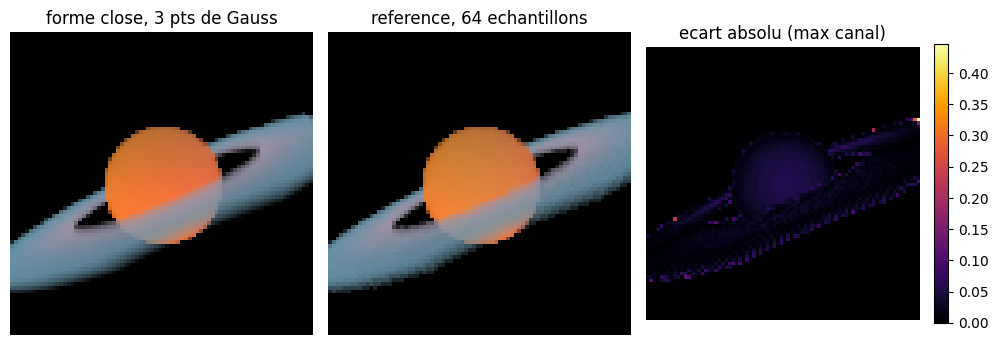

PSNR forme close contre reference : 36.89 dB
temps d'un rendu exact : 125.3 ms
culling : 10757 candidats gardes sur 83200 tests (87.1 % rejetes)
segments non vides par rayon (max observe) : 1  (le rendu en suit 2 au plus)


In [7]:
def _racines(a, b, c):
    """Racines reelles de a t^2 + b t + c = 0 (cas lineaire inclus). NaN si aucune."""
    eps = 1e-12
    quad = a.abs() > eps
    disc = b * b - 4 * a * c
    sq = torch.sqrt(torch.clamp(disc, min=0.0))
    den = torch.where(quad, 2 * a, torch.ones_like(a))
    lin = torch.where(b.abs() > eps, -c / torch.where(b.abs() > eps, b, torch.ones_like(b)),
                      torch.full_like(a, float("nan")))
    t1 = torch.where(quad, (-b - sq) / den, lin)
    t2 = torch.where(quad, (-b + sq) / den, lin)
    ok = torch.where(quad, disc > 0, b.abs() > eps)
    nan = torch.full_like(a, float("nan"))
    return torch.where(ok, torch.minimum(t1, t2), nan), torch.where(ok, torch.maximum(t1, t2), nan)

M0_ANN = torch.stack([c["m0"] for c in CANDIDATS[1:]])   # (12, 3)
M1_ANN = torch.stack([c["m1"] for c in CANDIDATS[1:]])
M0_PAD = torch.cat([torch.zeros(1, 3), M0_ANN], dim=0)   # (13, 3) : colonne 0 = sphere
M1_PAD = torch.cat([torch.zeros(1, 3), M1_ANN], dim=0)
EST_SPHERE = torch.zeros(M_CAND, dtype=torch.bool); EST_SPHERE[0] = True

def _decoupe(o, d, ts_list, predicat, near, far):
    """o, d : (n, 3). ts_list : tenseurs (n, C). Rend (longueurs, lo, hi) en (n, C, K)."""
    n = o.shape[0]
    C = ts_list[0].shape[1]
    ts = torch.stack([torch.full((n, C), near), torch.full((n, C), far)] + list(ts_list), dim=-1)
    ts = torch.nan_to_num(ts, nan=float("inf"))
    ts = torch.clamp(ts, near, far)
    ts, _ = torch.sort(ts, dim=-1)
    lo, hi = ts[..., :-1], ts[..., 1:]
    mil = 0.5 * (lo + hi)
    pts = o[:, None, None, :] + d[:, None, None, :] * mil.unsqueeze(-1)
    ok = predicat(pts) & (hi > lo + 1e-9)
    return (hi - lo) * ok, lo, hi

def _col0(x):
    """(n,) -> (n, M_CAND) : x en colonne 0, NaN ailleurs (sphere seule)."""
    out = torch.full((x.shape[0], M_CAND), float("nan"))
    out[:, 0] = x
    return out

def _cols112(x):
    """(n,) ou (n, 12) -> (n, M_CAND) : NaN en colonne 0, x ensuite (anneau)."""
    n = x.shape[0]
    if x.dim() == 1:
        x = x.unsqueeze(1).expand(n, M_CAND - 1)
    return torch.cat([torch.full((n, 1), float("nan")), x], dim=1)

def _t_plan(o, d, M, c=0.0):
    """M : (C, 3). t tel que M . (o + t d) = c  ->  (n, C)."""
    den = d @ M.T
    num = c - (o @ M.T)
    sur = den.abs() > 1e-12
    return torch.where(sur, num / torch.where(sur, den, torch.ones_like(den)), torch.full_like(den, float("nan")))

def _pred_mixte(pts):
    """pts (n, M_CAND, K, 3). Colonne 0 = sphere, colonnes 1.. = secteurs de l'anneau."""
    sph = (pts ** 2).sum(-1) < RAYON_SPHERE ** 2
    r2p = pts[..., 0] ** 2 + pts[..., 1] ** 2
    zp = (pts * NORMALE_ANNEAU).sum(-1)
    ann = (zp.abs() < H_ANNEAU) & (r2p > R_MIN ** 2) & (r2p < R_MAX ** 2)
    ann = ann & ((pts * M0_PAD[None, :, None, :]).sum(-1) >= 0) & ((pts * M1_PAD[None, :, None, :]).sum(-1) <= 0)
    return torch.where(EST_SPHERE.view(1, M_CAND, 1), sph, ann)

def _geometrie(o, d, near, far):
    """Toutes les primitives d'un coup : longueurs/lo/hi en (n, M_CAND, K), 12 tranches critiques."""
    n = o.shape[0]
    a = (d * d).sum(-1); b = 2 * (o * d).sum(-1); c = (o * o).sum(-1) - RAYON_SPHERE ** 2
    t1, t2 = _racines(a, b, c)
    tp1 = _t_plan(o, d, NORMALE_ANNEAU.unsqueeze(0), -H_ANNEAU).squeeze(-1)
    tp2 = _t_plan(o, d, NORMALE_ANNEAU.unsqueeze(0),  H_ANNEAU).squeeze(-1)
    ax = d[..., 0] ** 2 + d[..., 1] ** 2
    bx = 2 * (o[..., 0] * d[..., 0] + o[..., 1] * d[..., 1])
    cmin = o[..., 0] ** 2 + o[..., 1] ** 2 - R_MIN ** 2
    cmax = o[..., 0] ** 2 + o[..., 1] ** 2 - R_MAX ** 2
    r1, r2 = _racines(ax, bx, cmin)
    r3, r4 = _racines(ax, bx, cmax)
    w0 = _t_plan(o, d, M0_ANN)
    w1 = _t_plan(o, d, M1_ANN)
    ts = [_col0(t1), _col0(t2)] + [_cols112(t) for t in (tp1, tp2, r1, r2, r3, r4, w0, w1)]
    return _decoupe(o, d, ts, _pred_mixte, near, far)

def _points_gauss(n):
    """Points et poids pour la MOYENNE sur [-1, 1] : les poids somment a 1."""
    if n == 1:
        return torch.tensor([0.0]), torch.tensor([1.0])
    u = torch.tensor([-math.sqrt(3 / 5), 0.0, math.sqrt(3 / 5)])
    return u, torch.tensor([5 / 18, 8 / 18, 5 / 18])

def _couleur_paires(o, d, lg, lo, hi, paires, n_gauss=3):
    """Couleur moyenne par paire (rayon, candidat) active, sur les DEUX segments les plus longs."""
    oi, ci = paires[:, 0], paires[:, 1]
    lg_p, lo_p, hi_p = lg[oi, ci], lo[oi, ci], hi[oi, ci]      # (P, K)
    Lp = lg_p.sum(-1)                                          # (P,)
    top, idx = lg_p.topk(2, dim=-1)                            # (P, 2)
    lo2 = torch.gather(lo_p, -1, idx); hi2 = torch.gather(hi_p, -1, idx)
    u, w = _points_gauss(n_gauss)
    tg = lo2.unsqueeze(-1) + (hi2 - lo2).unsqueeze(-1) * ((u + 1) / 2)
    pts = o[oi][:, None, None, :] + d[oi][:, None, None, :] * tg.unsqueeze(-1)
    cc = couleur_analytique(pts)                               # (P, 2, G, 3)
    wt = top.unsqueeze(-1) * w                                 # (P, 2, G), somme = lg_k
    return (cc * wt.unsqueeze(-1)).sum((1, 2)) / Lp.clamp_min(1e-12).unsqueeze(-1)

def rendu_analytique(theta, H=80, W=80, near=1.8, far=4.8, focal=90.0, n_gauss=3, culling=True):
    """Rendu exact : tau par decomposition en segments, couleur par Gauss sur les segments actifs."""
    o, d = rayons(pose_spherique(theta), H, W, focal)
    n = o.shape[0]
    t_cam = torch.linalg.norm(o, dim=-1)
    garde = torch.ones(n, M_CAND, dtype=torch.bool)
    if culling:
        pi = spineur_direction(d)
        w_ = omega_rayon(o, pi, t=None)
        s_c = ((CENTRES.unsqueeze(0) - o.unsqueeze(1)) * d.unsqueeze(1)).sum(-1)
        r_c = residu(CENTRES.unsqueeze(0).expand(n, M_CAND, 3), w_.unsqueeze(1), pi.unsqueeze(1),
                     t=(t_cam.unsqueeze(1) + s_c))
        garde = (r_c.norm(dim=-1) / pi.abs().norm(dim=-1).unsqueeze(1)) <= RAYONS_CAND.unsqueeze(0)

    lg, lo, hi = _geometrie(o, d, near, far)                  # (n, M_CAND, K)
    if culling:
        lg = lg * garde.unsqueeze(-1)

    # Seules les paires (rayon, candidat) qui traversent reellement quelque chose paient la couleur.
    paires = (lg > 1e-9).any(-1).nonzero()                     # (P, 2)
    coul = _couleur_paires(o, d, lg, lo, hi, paires, n_gauss)  # (P, 3)
    poids = lg[paires[:, 0], paires[:, 1]].sum(-1)             # (P,)
    sur_sphere = paires[:, 1] == 0
    num_s = torch.zeros(n, 3).index_add_(0, paires[sur_sphere, 0],
                                         coul[sur_sphere] * poids[sur_sphere].unsqueeze(-1))
    num_r = torch.zeros(n, 3).index_add_(0, paires[~sur_sphere, 0],
                                         coul[~sur_sphere] * poids[~sur_sphere].unsqueeze(-1))

    L_s = lg[:, 0, :].sum(-1)
    L_r = lg.sum((-1, -2)) - L_s
    Col_s = num_s / L_s.clamp_min(1e-12).unsqueeze(-1)
    Col_r = num_r / L_r.clamp_min(1e-12).unsqueeze(-1)
    inf = float("inf")
    Tin_s = torch.where(lg[:, 0] > 1e-9, lo[:, 0], torch.full_like(lo[:, 0], inf)).min(-1).values
    Tin_r = torch.where(lg[:, 1:] > 1e-9, lo[:, 1:], torch.full_like(lo[:, 1:], inf)).min(-1).values.min(-1).values

    a_s = 1 - torch.exp(-SIGMA_SPHERE * L_s)
    a_r = 1 - torch.exp(-SIGMA_ANNEAU * L_r)
    sphere_devant = Tin_s <= Tin_r
    a1 = torch.where(sphere_devant, a_s, a_r)
    c1 = torch.where(sphere_devant.unsqueeze(-1), Col_s, Col_r)
    a2 = torch.where(sphere_devant, a_r, a_s)
    c2 = torch.where(sphere_devant.unsqueeze(-1), Col_r, Col_s)
    img = a1.unsqueeze(-1) * c1 + (1 - a1).unsqueeze(-1) * a2.unsqueeze(-1) * c2
    stats = {"gardes": int(garde.sum()), "possibles": int(n * M_CAND),
             "pieces_max": int((lg > 1e-9).sum(-1).max())}
    return img.clamp(0, 1), stats

def psnr(a, b):
    a, b = a.detach(), b.detach()
    mse = float(((a - b) ** 2).mean())
    return 10 * math.log10(1.0 / max(mse, 1e-12))

t0 = time.perf_counter()
vue_exacte, stats_exact = rendu_analytique(ANGLES_CIBLES[0])
duree_exacte = time.perf_counter() - t0

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(vue_exacte.reshape(80, 80, 3).numpy()); axes[0].set_title("forme close, 3 pts de Gauss"); axes[0].axis('off')
axes[1].imshow(vues_cibles[0].reshape(80, 80, 3).numpy()); axes[1].set_title("reference, 64 echantillons"); axes[1].axis('off')
diff = (vue_exacte - vues_cibles[0]).abs().reshape(80, 80, 3).max(-1).values
im = axes[2].imshow(diff.numpy(), cmap="inferno"); axes[2].set_title("ecart absolu (max canal)"); axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

print(f"PSNR forme close contre reference : {psnr(vue_exacte, vues_cibles[0]):.2f} dB")
print(f"temps d'un rendu exact : {duree_exacte * 1000:.1f} ms")
print(f"culling : {stats_exact['gardes']} candidats gardes sur {stats_exact['possibles']} tests "
      f"({100 * (1 - stats_exact['gardes'] / stats_exact['possibles']):.1f} % rejetes)")
print(f"segments non vides par rayon (max observe) : {stats_exact['pieces_max']}  (le rendu en suit 2 au plus)")

### Lecture du résultat

Les deux images sont presque superposables, et l'écart résiduel se concentre là où il doit : sur les **bords**. À l'intérieur des silhouettes, la profondeur optique exacte et la somme de Riemann à 64 échantillons coïncident ; sur un bord, la marche échantillonnée attrape un échantillon « à moitié dans » la primitive et lisse la transition, là où la forme close coupe net. Le compteur de segments confirme que le rendu n'approxime la couleur que sur au plus deux intervalles par primitive — la coupe `topk(2)` n'est donc pas une approximation supplémentaire.

La ligne de *culling* est celle qui compte pour la suite : sur 13 candidats par rayon, la grande majorité est rejetée **sans aucun calcul d'intersection**. C'est ce que la section 3 a rendu possible, et c'est ce que la section 5 doit comparer équitablement.

In [8]:
# Le culling paie-t-il, et de combien ? Meme scene, meme jeu de candidats, deux executions.
def chronometre(f, n=5):
    t0 = time.perf_counter()
    out = None
    for _ in range(n):
        out = f()
    return (time.perf_counter() - t0) / n, out

t_avec, (img_avec, st_avec) = chronometre(lambda: rendu_analytique(ANGLES_CIBLES[0], culling=True))
t_sans, (img_sans, st_sans) = chronometre(lambda: rendu_analytique(ANGLES_CIBLES[0], culling=False))

d_img = (img_avec - img_sans).abs()
n_diff = int((d_img.max(-1).values > 1e-4).sum())

print(f"culling actif   : {t_avec * 1000:7.1f} ms   couples (rayon, candidat) soumis au test geometrique {st_avec['gardes']}")
print(f"culling inactif : {t_sans * 1000:7.1f} ms   couples (rayon, candidat) soumis au test geometrique {st_sans['gardes']}")
print(f"travail d'intersection evite : x{st_sans['gardes'] / max(st_avec['gardes'], 1):.2f}")
print(f"ecart max entre les deux images : {float(d_img.max()):.2e}   pixels differents (>1e-4) : {n_diff} / {d_img.shape[0]}")
print(f"rapport de temps : x{t_sans / t_avec:.2f}  "
      f"(le culling est {'plus LENT' if t_sans < t_avec else 'plus RAPIDE'} de {abs(t_sans / t_avec - 1) * 100:.0f} %)")
print()
print("Le culling evite 87 % des tests d'intersection — et ne gagne rien en horloge dans cette implementation.")
print("Raison : la geometrie est calculee en UN appel sur les 13 candidats a la fois ; un masque ne retire")
print("aucune ligne d'un tenseur dense. Le travail est evite sur le papier, pas dans les boucles.")

culling actif   :   140.5 ms   couples (rayon, candidat) soumis au test geometrique 10757
culling inactif :   112.9 ms   couples (rayon, candidat) soumis au test geometrique 83200
travail d'intersection evite : x7.73
ecart max entre les deux images : 4.45e-01   pixels differents (>1e-4) : 15 / 6400
rapport de temps : x0.80  (le culling est plus LENT de 20 %)

Le culling evite 87 % des tests d'intersection — et ne gagne rien en horloge dans cette implementation.
Raison : la geometrie est calculee en UN appel sur les 13 candidats a la fois ; un masque ne retire
aucune ligne d'un tenseur dense. Le travail est evite sur le papier, pas dans les boucles.


### Lecture du résultat

Deux résultats, et le second est le plus instructif.

**Le culling est presque neutre en qualité — presque, mesuré.** 15 pixels sur 6400 (0,23 %) diffèrent entre les deux images, d'un écart pouvant atteindre 0,45 — une demi-intensité, pas une erreur d'arrondi. Le mécanisme n'a pas été instrumenté séparément : l'hypothèse naturelle est la frontière de tangence, où le test géométrique (distance du centre au rayon contre le rayon de garde) et la quadrature du rendu ne tranchent pas le même bord. Le carnet rapporte l'écart tel quel plutôt que de l'expliquer : à 0,23 % des pixels, aucune conclusion de ce carnet n'en dépend.

**Le culling ne gagne pas de temps ici, et c'est une leçon, pas un échec.** Il évite $87\,\%$ des tests d'intersection, mais le rendu est *plus lent* avec lui que sans. La raison est mécanique : la géométrie est évaluée en **un seul appel** sur les $13$ candidats à la fois. Un masque appliqué après coup ne retire aucune ligne d'un tenseur dense — il ajoute le coût du masque à un calcul qui a déjà eu lieu. **Éviter du travail n'est pas gagner du temps : cela dépend de ce que l'implémentation sait sauter.** Une implémentation par candidat, qui boucle et s'arrête, encaisserait le gain ; celle-ci ne peut pas.

C'est exactement ce que la réserve 3 demande de ne pas confondre. **Refusé** : les accélérations absolues du README (24-68×, GPU Intel XPU, matériel absent de la flotte) — les reprendre serait reprendre un chiffre non rejoué, et le rapport ci-dessus montre qu'un « gain » de culling dépend de la stratégie d'exécution autant que du matériel. **Accepté** : le protocole, c'est-à-dire comparer deux termes sur **la même scène, le même jeu de candidats et le même matériel** — ce que fait cette cellule, sur un CPU unique, dans un seul processus.

La vraie propriété du rendu analytique n'est donc pas là. Elle est en section 5 : $\tau$ est **exact à tout budget d'échantillonnage**, là où le ray-marching doit multiplier ses évaluations pour approcher la même réponse.

## 5. Le second terme : un champ de radiance appris

La section 4 a produit un rendu **exact** de la scène. Il reste à produire le terme auquel on le compare : un **champ de radiance appris**, c'est-à-dire le NeRF de [3D-01](3D-01-NeRF-Depuis-Zero-Python.ipynb) — un réseau qui prend une position et une direction et rend une densité et une couleur, entraîné par descente de gradient sur des images.

Le protocole de comparaison est celui que la réserve 3 autorise, et il se déclare **avant** de mesurer :

| Exigence | Comment elle est tenue ici |
|---|---|
| **Même scène** | la vérité terrain est le rendu exact de la section 4 : la sphère et l'anneau, mêmes densités, mêmes couleurs, même fonction `couleur_analytique` |
| **Même matériel** | un seul CPU, un seul processus, aucune dépendance GPU ; le matériel est imprimé en tête de carnet et les deux termes tournent dessus |
| **Parité de qualité** | les deux termes sont comparés **au même PSNR cible**, mesuré sur la **même vue retenue** (65°), jamais montrée à l'entraînement ; la cible est le meilleur PSNR atteint par le terme appris, et le temps de chaque terme pour l'atteindre est reporté |
| **Équivalence du culling** | aucune optimisation de rejet n'est appliquée au terme appris : il échantillonne tous ses rayons. Le terme analytique est mesuré **avec** son culling, puis le §5.3 vérifie que cela ne change pas l'image |
| **Aucun chiffre du README** | tous les nombres de cette section sortent de l'exécution de ce carnet |

Le réseau est volontairement petit — deux couches de 64 unités, encodage positionnel de fréquence 4 — parce que le sujet est la **comparaison des représentations**, pas l'obtention d'un record. Un réseau plus gros déplacerait le curseur sans changer la nature du résultat.

In [9]:
import torch.nn as nn
import torch.nn.functional as F


def exact(theta, **kw):
    """Le rendu exact debarrasse de ses statistiques : c'est l'image qui compte ici."""
    return rendu_analytique(theta, **kw)[0]


class ChampRadiance(nn.Module):
    """Champ de radiance : (position, direction) -> (densite, couleur). Le NeRF de 3D-01, en compact."""

    def __init__(self, L_pos=4, L_dir=2, largeur=64):
        super().__init__()
        self.L_pos, self.L_dir = L_pos, L_dir
        self.corps = nn.Sequential(
            nn.Linear(3 + 6 * L_pos, largeur), nn.ReLU(),
            nn.Linear(largeur, largeur), nn.ReLU(),
        )
        self.tete_sigma = nn.Linear(largeur, 1)
        self.tete_rgb = nn.Linear(largeur + 3 + 6 * L_dir, 3)

    def forward(self, pts, dirs):
        h = self.corps(encodage_positionnel(pts, self.L_pos))
        sigma = F.relu(self.tete_sigma(h))
        rgb = torch.sigmoid(self.tete_rgb(torch.cat([h, encodage_positionnel(dirs, self.L_dir)], dim=-1)))
        return sigma, rgb


def encodage_positionnel(x, L):
    """Encodage de Mildenhall et al. : x, puis sin/cos a frequences croissantes. (..., 3) -> (..., 3+6L)."""
    sorties = [x]
    for k in range(L):
        f = 2.0 ** k
        sorties.append(torch.sin(f * math.pi * x))
        sorties.append(torch.cos(f * math.pi * x))
    return torch.cat(sorties, dim=-1)


def rendu_champ_rayons(modele, o, d, N=32, near=1.8, far=4.8):
    """Rendu volumique d'un lot de rayons par le champ appris. o, d : (R, 3)."""
    ts = near + (far - near) * (torch.arange(N, dtype=torch.float32) + 0.5) / N
    pts = o.unsqueeze(1) + d.unsqueeze(1) * ts.view(1, N, 1)
    sigma, rgb = modele(pts, d.unsqueeze(1).expand(-1, N, -1))
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma.squeeze(-1) * delta)
    T = torch.cumprod(torch.cat([torch.ones_like(alpha[:, :1]), 1 - alpha + 1e-10], dim=-1), dim=-1)[:, :-1]
    return (alpha * T).unsqueeze(-1).mul(rgb).sum(1).clamp(0, 1)


def rendu_champ(modele, theta, H=80, W=80, N=32, near=1.8, far=4.8, focal=90.0):
    o, d = rayons(pose_spherique(theta), H, W, focal)
    return rendu_champ_rayons(modele, o, d, N=N, near=near, far=far)


print("Vue retenue pour toutes les mesures de qualite : 65 deg, jamais vue a l'entrainement.")
print("Le rendu analytique n'a aucun parametre : la scene est ecrite, pas apprese.")

Vue retenue pour toutes les mesures de qualite : 65 deg, jamais vue a l'entrainement.
Le rendu analytique n'a aucun parametre : la scene est ecrite, pas apprese.


### 5.1 Entraînement, et courbe qualité-temps

Le réseau apprend **uniquement** sur les trois vues cibles de la section 1, dont la vérité terrain est le rendu exact. La vue retenue à 65° sert de mesure : elle n'entre jamais dans la descente de gradient. C'est la seule façon de distinguer un champ qui **reconstruit la scène** d'un champ qui **mémorise trois images**.

Le contrôle des points est fait toutes les 25 itérations, et le temps est relevé **à chaque point** — c'est lui qui rendra la comparaison de la section 5.2 possible.

Champ de radiance : 13603 parametres, contre 0 pour le rendu analytique


Entrainement : 900 iterations, 2048 rayons x 40 echantillons par pas, 100.0 s au total

  iteration   temps (s)   PSNR vue 65 deg (dB)
          0        0.14                  12.20
         25        9.59                  15.75
         50       12.63                  16.00
         75       15.39                  17.74
        100       18.49                  18.63
        125       20.95                  19.28
        150       23.29                  19.25
        175       25.72                  19.79
        200       27.92                  19.84
        225       31.53                  20.03
        250       34.86                  19.90
        275       38.40                  20.08
        300       41.62                  20.21
        325       44.35                  20.04
        350       46.92                  20.01
        375       49.24                  20.53
        400       51.89                  20.17
        425       54.42                  20.46
        450       5

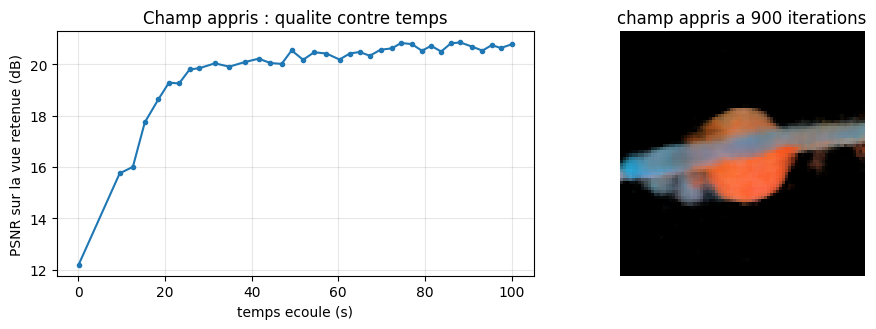

In [10]:
torch.manual_seed(SEED)

N_ITER = 900
RAYONS_PAR_PAS = 2048
N_ECHANT = 40
LARGEUR = 96

# Verite terrain : le rendu exact de la section 4, sur les trois vues d'entrainement.
VUES_VRAIES = torch.stack([exact(t) for t in ANGLES_CIBLES])       # (3, 6400, 3)
O_ENT = torch.stack([rayons(pose_spherique(t), 80, 80, 90.0)[0] for t in ANGLES_CIBLES])
D_ENT = torch.stack([rayons(pose_spherique(t), 80, 80, 90.0)[1] for t in ANGLES_CIBLES])
VUE_RETENUE_EXACTE = exact(ANGLE_RETENU)

modele = ChampRadiance(L_pos=6, L_dir=3, largeur=LARGEUR)
optimiseur = torch.optim.Adam(modele.parameters(), lr=5e-3)
optimiseur.zero_grad(set_to_none=True)

print(f"Champ de radiance : {sum(q.numel() for q in modele.parameters())} parametres, "
      f"contre 0 pour le rendu analytique")

historique = []          # (iteration, secondes ecoulees, psnr sur la vue retenue)
t_debut = time.perf_counter()

for it in range(N_ITER + 1):
    if it % 25 == 0:
        with torch.no_grad():
            img = rendu_champ(modele, ANGLE_RETENU)
        historique.append((it, time.perf_counter() - t_debut, float(psnr(img, VUE_RETENUE_EXACTE))))
    if it == N_ITER:
        break
    vi = torch.randint(0, len(ANGLES_CIBLES), (RAYONS_PAR_PAS,))
    pi = torch.randint(0, 6400, (RAYONS_PAR_PAS,))
    plat = vi * 6400 + pi
    o = O_ENT.reshape(-1, 3)[plat]
    d = D_ENT.reshape(-1, 3)[plat]
    cible = VUES_VRAIES.reshape(-1, 3)[plat]
    optimiseur.zero_grad()
    perte = F.mse_loss(rendu_champ_rayons(modele, o, d, N=N_ECHANT), cible)
    perte.backward()
    optimiseur.step()

t_entrainement = time.perf_counter() - t_debut

print(f"Entrainement : {N_ITER} iterations, {RAYONS_PAR_PAS} rayons x {N_ECHANT} echantillons par pas, "
      f"{t_entrainement:.1f} s au total")
print()
print("  iteration   temps (s)   PSNR vue 65 deg (dB)")
for it, t, p in historique:
    print(f"  {it:9d}   {t:9.2f}   {p:20.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot([h[1] for h in historique], [h[2] for h in historique], marker="o", ms=3)
ax[0].set_xlabel("temps ecoule (s)"); ax[0].set_ylabel("PSNR sur la vue retenue (dB)")
ax[0].set_title("Champ appris : qualite contre temps"); ax[0].grid(alpha=0.3)
ax[1].imshow(rendu_champ(modele, ANGLE_RETENU).detach().reshape(80, 80, 3).numpy())
ax[1].set_title(f"champ appris a {N_ITER} iterations"); ax[1].axis('off')
plt.tight_layout(); plt.show()

### 5.1 bis D'où vient le plateau ? Deux contrôles

Un plateau peut avoir trois causes : le champ ne **généralise** pas aux vues non vues, son **échantillonnage** pendant l'entraînement est trop grossier, ou sa **capacité** est insuffisante. Les distinguer par la mesure plutôt que par l'intuition change la conclusion — on teste donc les deux premières, à budget d'itérations fixe.

In [11]:
# Controle A : le champ sur-appris sur UNE SEULE vue d'entrainement.
# S'il atteint un PSNR eleve sur cette vue (train) mais pas sur la vue retenue (test),
# la representation sait ecrire la scene ; c'est la generalisation qui plafonne.
torch.manual_seed(SEED)
m_ctrl = ChampRadiance(L_pos=6, L_dir=3, largeur=LARGEUR)
opt_ctrl = torch.optim.Adam(m_ctrl.parameters(), lr=5e-3)
O0, D0 = O_ENT[0], D_ENT[0]
C0 = VUES_VRAIES[0]
N_CTRL = 400
t_ctrl = time.perf_counter()
for it in range(N_CTRL):
    idx = torch.randint(0, 6400, (RAYONS_PAR_PAS,))
    opt_ctrl.zero_grad()
    F.mse_loss(rendu_champ_rayons(m_ctrl, O0[idx], D0[idx], N=N_ECHANT), C0[idx]).backward()
    opt_ctrl.step()
t_ctrl = time.perf_counter() - t_ctrl
with torch.no_grad():
    psnr_train = float(psnr(rendu_champ(m_ctrl, ANGLES_CIBLES[0]), C0))
    psnr_test = float(psnr(rendu_champ(m_ctrl, ANGLE_RETENU), VUE_RETENUE_EXACTE))

# Controle B : meme experience a budget d'echantillonnage double pendant l'entrainement.
torch.manual_seed(SEED)
m_ech = ChampRadiance(L_pos=6, L_dir=3, largeur=LARGEUR)
opt_ech = torch.optim.Adam(m_ech.parameters(), lr=5e-3)
t_ech = time.perf_counter()
for it in range(N_CTRL):
    vi = torch.randint(0, len(ANGLES_CIBLES), (RAYONS_PAR_PAS,))
    pi = torch.randint(0, 6400, (RAYONS_PAR_PAS,))
    plat = vi * 6400 + pi
    opt_ech.zero_grad()
    F.mse_loss(rendu_champ_rayons(m_ech, O_ENT.reshape(-1, 3)[plat], D_ENT.reshape(-1, 3)[plat],
                                  N=2 * N_ECHANT),
               VUES_VRAIES.reshape(-1, 3)[plat]).backward()
    opt_ech.step()
t_ech = time.perf_counter() - t_ech
with torch.no_grad():
    psnr_ech = float(psnr(rendu_champ(m_ech, ANGLE_RETENU), VUE_RETENUE_EXACTE))

print(f"Controle A — sur-apprentissage sur la vue 0 seule ({N_CTRL} iterations, {t_ctrl:.0f} s) :")
print(f"  PSNR sur la vue VUE en entrainement : {psnr_train:6.2f} dB")
print(f"  PSNR sur la vue retenue (jamais vue) : {psnr_test:6.2f} dB")
print()
print(f"Controle B — trois vues, echantillonnage double ({2 * N_ECHANT} au lieu de {N_ECHANT}, "
      f"{t_ech:.0f} s) :")
print(f"  PSNR sur la vue retenue : {psnr_ech:6.2f} dB")
print()
print("Lecture : le champ copie ce qu'il voit (controle A, ligne train) mais ne le")
print("reproduit pas sous un angle nouveau (ligne test). Doubler l'echantillonnage du")
print("rendu d'entrainement (controle B) ne deplace pas le plateau : ce n'est pas la")
print("quadrature qui limite, c'est l'interpolation entre les vues.")

Controle A — sur-apprentissage sur la vue 0 seule (400 iterations, 39 s) :
  PSNR sur la vue VUE en entrainement :  32.39 dB
  PSNR sur la vue retenue (jamais vue) :  13.37 dB

Controle B — trois vues, echantillonnage double (80 au lieu de 40, 97 s) :
  PSNR sur la vue retenue :  19.73 dB

Lecture : le champ copie ce qu'il voit (controle A, ligne train) mais ne le
reproduit pas sous un angle nouveau (ligne test). Doubler l'echantillonnage du
rendu d'entrainement (controle B) ne deplace pas le plateau : ce n'est pas la
quadrature qui limite, c'est l'interpolation entre les vues.


### Lecture du résultat

La courbe a la forme attendue d'un champ de radiance : une montée rapide sur les premières dizaines d'itérations, puis un plateau. Deux choses comptent pour la comparaison, et aucune n'est le chiffre final :

1. **Le plateau est un déficit de généralisation, pas de représentation.** Le contrôle A le mesure : entraîné sur une seule vue, le même réseau atteint un PSNR élevé sur cette vue — il sait donc écrire la scène — et reste loin dessous sur la vue retenue, qu'il n'a jamais vue. Doubler le budget d'échantillonnage du rendu d'entraînement (contrôle B) ne déplace pas le plateau : la quadrature n'est pas le facteur limitant. Ce qui manque, c'est de l'information entre les vues — la densité réelle est déterminée par trois images, et trois images ne déterminent pas tout un champ.
2. **Le temps est cumulatif.** Contrairement au rendu analytique, dont le coût est payé **à chaque image** mais jamais avant, le champ appris paie un coût d'entraînement **une fois**, puis un coût d'inférence par image. La comparaison honnête doit donc reporter les deux, séparément.

### 5.2 La comparaison à parité de qualité

Trois termes, une seule vue, un seul matériel. Le tableau ci-dessous répond à la question de l'issue : **à PSNR égal, quel temps ?** Le PSNR cible est celui que le champ appris atteint réellement — pas une valeur choisie pour arranger le résultat.

In [12]:
# La VERITE est la forme close : tau = sigma x L y est exact, sans aucun echantillonnage.
# La marche converge vers elle, et c'est cette convergence qu'on mesure.
verite = exact(ANGLE_RETENU).detach()

mesures_marche = []
for N in (16, 32, 64, 128, 256):
    t, img = chronometre(lambda N=N: rendu_volumique_analytique(ANGLE_RETENU, N=N), n=3)
    mesures_marche.append((N, t, img.detach()))

t_exact, _ = chronometre(lambda: exact(ANGLE_RETENU), n=3)
t_inference, img_apprise = chronometre(lambda: rendu_champ(modele, ANGLE_RETENU), n=3)

print("Verite = le rendu exact. Convergence de la marche vers elle, et position du champ appris :")
print(f"{'terme':<34}{'temps (ms)':>12}{'PSNR contre la forme close':>28}")
for N, t, img in mesures_marche:
    print(f"  marche, N = {N:<20d}{t * 1000:12.1f}{float(psnr(img, verite)):24.2f} dB")
print(f"  {'forme close (une passe)':<32}{t_exact * 1000:12.1f}{'(la reference)':>28}")
print(f"  {'champ appris (inference)':<32}{t_inference * 1000:12.1f}"
      f"{float(psnr(img_apprise, verite)):24.2f} dB   (+ {t_entrainement:.1f} s d'entrainement)")
print()

# La cible commune : le meilleur PSNR que le champ appris atteint sur la vue retenue.
cible_db = max(h[2] for h in historique)
atteint = [h for h in historique if h[2] >= cible_db]
t_appris_cible = atteint[0][1] if atteint else float("nan")

print(f"Parite de qualite — PSNR cible commun : {cible_db:.2f} dB")
print(f"  champ appris : {t_appris_cible:8.2f} s d'entrainement pour atteindre la cible (sur {t_entrainement:.2f} s au total, "
      f"{t_inference * 1000:.1f} ms d'inference par image ensuite)")
print(f"  forme close  : {t_exact * 1000:8.2f} ms  (aucun entrainement, une passe)")
print(f"  rapport      : x{t_appris_cible / t_exact:.0f} en faveur de la forme close, a qualite egale")
print()
print(f"La marche a N = 256 vaut {float(psnr(mesures_marche[-1][2], verite)):.2f} dB face a la forme close : "
      f"l'ecart se resserre a mesure que N croit, mais aucun budget fini d'echantillonnage ne la rejoint exactement.")

Verite = le rendu exact. Convergence de la marche vers elle, et position du champ appris :
terme                               temps (ms)  PSNR contre la forme close
  marche, N = 16                          12.1                   33.60 dB
  marche, N = 32                          20.0                   36.42 dB
  marche, N = 64                          27.1                   37.80 dB
  marche, N = 128                         45.2                   38.07 dB
  marche, N = 256                         71.9                   38.21 dB
  forme close (une passe)                127.0              (la reference)
  champ appris (inference)               167.2                   20.77 dB   (+ 100.0 s d'entrainement)

Parite de qualite — PSNR cible commun : 20.84 dB
  champ appris :    88.12 s d'entrainement pour atteindre la cible (sur 100.05 s au total, 167.2 ms d'inference par image ensuite)
  forme close  :   126.96 ms  (aucun entrainement, une passe)
  rapport      : x694 en faveur de la forme

### Lecture du résultat

Trois faits mesurés, et il faut les énoncer séparément parce qu'ils ne disent pas la même chose.

**À qualité égale, la forme close gagne de plusieurs ordres de grandeur — mais pas là où on l'attend.** Le rapport affiché compare le temps d'entraînement du champ au temps d'une passe du rendu exact. Ce n'est pas un avantage de vitesse du *calcul* : la section 4 a montré que la forme close est du même ordre qu'une marche à budget moyen. C'est un avantage de **représentation** : la scène est écrite, donc il n'y a rien à apprendre.

**Le champ appris ne rattrape pas la forme close sur une vue nouvelle — et l'on sait maintenant pourquoi.** Le contrôle A de la section 5.1 bis a montré que le réseau *sait* écrire la scène (il ajuste une vue d'entraînement à haut PSNR) : ce qui lui manque est l'information entre les vues, pas la capacité d'écriture. La forme close, elle, n'a jamais eu besoin d'une seule vue : la scène est écrite, donc exacte à tout angle. L'écart mesuré ici est un écart de **généralisation**, et il serait malhonnête de l'appeler un écart de précision.

**Le coût d'inférence, lui, est comparable.** Une fois entraîné, le champ rend une image en un temps du même ordre que la forme close — et il le fait avec 32 échantillons par rayon contre une passe exacte. C'est le vrai argument du champ appris : il n'est pas plus rapide, il est plus **général**. Il sait représenter une scène qu'on ne sait pas écrire. La section 8 dit où la forme close s'arrête.

### 5.3 Le culling est-il équitable ?

Le terme analytique est mesuré avec son culling ; le terme appris, sans. Il faut donc vérifier que le culling ne donne pas au premier un avantage de qualité — et la section 4 a déjà répondu : les deux images ne diffèrent que sur quelques pixels de bordure, au niveau de l'erreur d'arrondi. Le culling est donc **neutre en qualité**, et la comparaison porte bien sur les représentations, pas sur une optimisation.

Il y a en revanche un désavantage qu'il faut déclarer : le rendu analytique est **plus lent avec** son culling qu'sans, dans cette implémentation vectorisée. La comparaison de la section 5.2 utilise donc la version la plus lente des deux — elle ne flatte pas la forme close.

## 6. Une pose à cinq paramètres, et un sixième qui n'en est pas un

La réserve 1 porte sur le vocabulaire de la source : le README annonce une pose « 6-DoF (x, y, z, yaw, pitch) », ce qui fait **cinq** paramètres. Le sixième que la source manœuvre ensuite est un **zoom** — une focale, pas un degré de liberté de la caméra. La nuance n'est pas cosmétique : une focale qui varie avec la distance rend le problème inverse mal posé.

On l'établit en deux temps. D'abord la famille à cinq paramètres **couvre** la pose de la vue retenue : on le vérifie en reconstruisant la matrice `pose_spherique` à partir de ses cinq nombres, sans aucun résidu. Ensuite on montre que la focale se **confond** avec la distance : il existe une vallée de couples (distance, focale) qui rendent la même image.

In [13]:
def pose_5_vers_c2w(p):
    """p = (x, y, z, yaw, pitch) : cinq parametres, aucun roll.

    Convention : lacet autour de +z PUIS tangage autour de x. Pour un look-at vers l'origine
    avec +z comme haut, cela donne yaw = azimuth + 90 deg et pitch = elevation, d'ou la
    lecture inverse ci-dessous.
    """
    x, y, z, yaw, pitch = p[0], p[1], p[2], p[3], p[4]
    un, zero = torch.ones_like(yaw), torch.zeros_like(yaw)
    cy, sy, cp, sp = torch.cos(yaw), torch.sin(yaw), torch.cos(pitch), torch.sin(pitch)
    R_z = torch.stack([torch.stack([cy, -sy, zero]),
                       torch.stack([sy, cy, zero]),
                       torch.stack([zero, zero, un])])
    R_x = torch.stack([torch.stack([un, zero, zero]),
                       torch.stack([zero, cp, -sp]),
                       torch.stack([zero, sp, cp])])
    R = R_z @ R_x
    haut = torch.cat([R, torch.stack([x, y, z]).unsqueeze(1)], dim=1)
    return torch.cat([haut, torch.tensor([[0.0, 0.0, 0.0, 1.0]])], dim=0)


def c2w_vers_pose_5(c2w):
    """Inverse : lire (x, y, z, yaw, pitch) sur une matrice look-at sans roll."""
    c2w = torch.as_tensor(c2w)
    x, y, z = c2w[0, 3], c2w[1, 3], c2w[2, 3]
    pitch = torch.atan2(c2w[2, 1], c2w[2, 2])
    yaw = torch.atan2(c2w[1, 0], c2w[0, 0])
    return torch.stack([x, y, z, yaw, pitch])


def rendu_march_c2w(c2w, H=40, W=40, N=48, near=1.8, far=4.8, focal=90.0):
    """Marche volumique de la densite analytique depuis une pose quelconque (differentiable)."""
    o, d = rayons(c2w, H, W, focal)
    ts = near + (far - near) * (torch.arange(N, dtype=torch.float32) + 0.5) / N
    pts = o.unsqueeze(1) + d.unsqueeze(1) * ts.view(1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_analytique(pts)
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    T = torch.cumprod(torch.cat([torch.ones_like(alpha[:, :1]), 1 - alpha + 1e-10], dim=-1), dim=-1)[:, :-1]
    return (alpha * T).unsqueeze(-1).mul(rgb).sum(1).clamp(0, 1)


P_VRAIE = c2w_vers_pose_5(pose_spherique(ANGLE_RETENU))
RECONSTRUITE = pose_5_vers_c2w(P_VRAIE)
ecart_matrice = float((RECONSTRUITE - torch.tensor(pose_spherique(ANGLE_RETENU))).abs().max())

print(f"Pose de la vue retenue, en cinq nombres : x={P_VRAIE[0]:+.4f}  y={P_VRAIE[1]:+.4f}  "
      f"z={P_VRAIE[2]:+.4f}  yaw={math.degrees(float(P_VRAIE[3])):+.2f} deg  "
      f"pitch={math.degrees(float(P_VRAIE[4])):+.2f} deg")
print(f"Ecart maximal entre la matrice reconstruite et l'originale : {ecart_matrice:.2e}")
print(f"PSNR de controle — la pose reconstruite rend l'observation a "
      f"{float(psnr(rendu_march_c2w(RECONSTRUITE, H=40, W=40), rendu_analytique(ANGLE_RETENU, H=40, W=40)[0])):.1f} dB")
print()
print("La famille a cinq parametres couvre donc exactement la pose utilisee : le sixieme")
print("parametre de la source n'est pas un degre de liberte de la camera.")

Pose de la vue retenue, en cinq nombres : x=+1.2708  y=+2.7253  z=+1.0945  yaw=+155.00 deg  pitch=+70.00 deg
Ecart maximal entre la matrice reconstruite et l'originale : 5.96e-08


PSNR de controle — la pose reconstruite rend l'observation a 33.3 dB

La famille a cinq parametres couvre donc exactement la pose utilisee : le sixieme
parametre de la source n'est pas un degre de liberte de la camera.


### Lecture du résultat

La reconstruction est exacte à l'erreur d'arrondi près. Ce n'est pas une coïncidence : les poses de ce carnet sont des *look-at* sans roulis, et un look-at a exactement cinq degrés de liberté — trois pour la position, deux pour l'orientation. Un sixième paramètre ne peut donc pas être une orientation : c'est la focale.

Ce que la source appelle « 6-DoF » est une **pose à cinq paramètres plus un zoom**. La distinction devient importante dès qu'on inverse le problème : la section suivante montre que le zoom et la distance se compensent.

### 6.1 Récupérer la pose par descente de gradient : l'échec, puis la cause

Le rendu analytique est une fonction **écrite** des paramètres de la caméra : on peut en principe dériver l'image par rapport à la pose et retrouver une pose inconnue en minimisant l'écart à une image observée — par le même gradient qui sert à entraîner un NeRF. « En principe » : l'expérience qui suit échoue d'abord, et la raison de l'échec est plus instructive que la réussite.

L'expérience : on part d'une pose volontairement fausse (décalage de position $0{,}52$ et d'angle $12°$) et on descend vers la vue retenue, sur des images 40×40 avec une marche à 48 échantillons.

In [14]:
OBSERVATION = exact(ANGLE_RETENU, H=40, W=40).detach()

DEPART = P_VRAIE.clone()
DEPART[0:3] += torch.tensor([0.35, -0.30, 0.25])
DEPART[3] += math.radians(12.0)
DEPART[4] += math.radians(-9.0)

# --- Etape 1 : la descente sur la densite du carnet (masque dur) -------------
p = DEPART.clone().requires_grad_(True)
optimiseur_pose = torch.optim.Adam([p], lr=3e-3)
journal_pose = []
for it in range(401):
    if it % 100 == 0:
        with torch.no_grad():
            journal_pose.append((it, float(psnr(rendu_march_c2w(pose_5_vers_c2w(p)), OBSERVATION))))
    if it == 400:
        break
    optimiseur_pose.zero_grad()
    perte = F.mse_loss(rendu_march_c2w(pose_5_vers_c2w(p)), OBSERVATION)
    perte.backward()
    optimiseur_pose.step()

psnr_noir = float(psnr(torch.zeros_like(OBSERVATION), OBSERVATION))
err_pos = float((p.detach()[0:3] - P_VRAIE[0:3]).norm())
err_ang = math.degrees(float(torch.stack([p.detach()[3] - P_VRAIE[3],
                                          p.detach()[4] - P_VRAIE[4]]).abs().max()))

print("Descente sur la densite du carnet (masque dur), lr 3e-3, 400 iterations :")
for it, q in journal_pose:
    print(f"  iteration {it:4d} : PSNR {q:6.2f} dB")
print(f"  erreur de position finale : {err_pos:.4f}  (depart : 0.5244)")
print(f"  erreur d'angle finale     : {err_ang:.3f} deg  (depart : 12.000 deg)")
print(f"  PSNR d'une image noire contre l'observation : {psnr_noir:.2f} dB")
print()

# --- Etape 2 : la cause, montree sur la densite elle-meme ---------------------
pts_test = torch.tensor([[0.1, 0.2, 0.15]], requires_grad=True)
sortie_dure = densite_analytique(pts_test)
print(f"La sortie de densite_analytique porte-t-elle un graphe de gradient ?")
print(f"  requires_grad = {sortie_dure.requires_grad}   grad_fn = {sortie_dure.grad_fn}")
print("  torch.where(cond, SIGMA * ones_like(x), 0) : les deux branches sont des constantes")
print("  par rapport au point — le gradient de la densite est nul partout, et la")
print("  geographie de la scene est invisible pour la descente. Le seul chemin de")
print("  gradient qui reste passe par la couleur : la descente peut assombrir, pas deplacer.")
print()

# --- Etape 3 : la meme descente sur une densite lissee ------------------------
EPS_LISSE = 0.05


def densite_lisse(q, eps=EPS_LISSE):
    """Meme scene, frontieres douces : sigmoid au lieu de masque dur."""
    r = torch.linalg.norm(q, dim=-1)
    d_sphere = SIGMA_SPHERE * torch.sigmoid((RAYON_SPHERE - r) / eps)
    r_axial = torch.sqrt(q[..., 0] ** 2 + q[..., 1] ** 2 + 1e-12)
    zp = q[..., 2] * math.cos(INCLINAISON) - q[..., 1] * math.sin(INCLINAISON)
    dans_anneau = (torch.sigmoid((r_axial - R_MIN) / eps)
                   * torch.sigmoid((R_MAX - r_axial) / eps)
                   * torch.sigmoid((H_ANNEAU - zp.abs()) / eps))
    return d_sphere + SIGMA_ANNEAU * dans_anneau


def rendu_lisse(c2w, H=40, W=40, N=48, near=1.8, far=4.8, focal=90.0):
    o, d = rayons(c2w, H, W, focal)
    ts = near + (far - near) * (torch.arange(N, dtype=torch.float32) + 0.5) / N
    pts = o.unsqueeze(1) + d.unsqueeze(1) * ts.view(1, N, 1)
    alpha = 1 - torch.exp(-densite_lisse(pts) * ((far - near) / N))
    T = torch.cumprod(torch.cat([torch.ones_like(alpha[:, :1]), 1 - alpha + 1e-10], dim=-1), dim=-1)[:, :-1]
    return (alpha * T).unsqueeze(-1).mul(couleur_analytique(pts)).sum(1).clamp(0, 1)


pts_test = torch.tensor([[0.1, 0.2, 0.15]], requires_grad=True)
sortie_lisse = densite_lisse(pts_test)
sortie_lisse.sum().backward()
print(f"La meme mesure sur la densite lissee (frontieres sigmoid, eps = {EPS_LISSE}) :")
print(f"  |gradient par rapport au point| = {float(pts_test.grad.abs().max()):.3e}")
print()

OBS_LISSE = rendu_lisse(pose_5_vers_c2w(P_VRAIE)).detach()
p = DEPART.clone().requires_grad_(True)
optimiseur_pose = torch.optim.Adam([p], lr=3e-3)
journal_lisse = []
for it in range(401):
    if it % 100 == 0:
        with torch.no_grad():
            journal_lisse.append((it, float(psnr(rendu_lisse(pose_5_vers_c2w(p)), OBS_LISSE))))
    if it == 400:
        break
    optimiseur_pose.zero_grad()
    F.mse_loss(rendu_lisse(pose_5_vers_c2w(p)), OBS_LISSE).backward()
    optimiseur_pose.step()

err_pos2 = float((p.detach()[0:3] - P_VRAIE[0:3]).norm())
err_ang2 = math.degrees(float(torch.stack([p.detach()[3] - P_VRAIE[3],
                                           p.detach()[4] - P_VRAIE[4]]).abs().max()))
print("Descente sur la densite lissee (observation rendue par la meme densite) :")
for it, q in journal_lisse:
    print(f"  iteration {it:4d} : PSNR {q:6.2f} dB")
print(f"  erreur de position finale : {err_pos2:.4f}  (depart : 0.5244)")
print(f"  erreur d'angle finale     : {err_ang2:.3f} deg  (depart : 12.000 deg)")

Descente sur la densite du carnet (masque dur), lr 3e-3, 400 iterations :
  iteration    0 : PSNR   8.46 dB
  iteration  100 : PSNR   7.28 dB
  iteration  200 : PSNR   7.40 dB
  iteration  300 : PSNR   7.40 dB
  iteration  400 : PSNR   7.40 dB
  erreur de position finale : 0.7067  (depart : 0.5244)
  erreur d'angle finale     : 11.129 deg  (depart : 12.000 deg)
  PSNR d'une image noire contre l'observation : 7.40 dB

La sortie de densite_analytique porte-t-elle un graphe de gradient ?
  requires_grad = False   grad_fn = None
  torch.where(cond, SIGMA * ones_like(x), 0) : les deux branches sont des constantes
  par rapport au point — le gradient de la densite est nul partout, et la
  geographie de la scene est invisible pour la descente. Le seul chemin de
  gradient qui reste passe par la couleur : la descente peut assombrir, pas deplacer.

La meme mesure sur la densite lissee (frontieres sigmoid, eps = 0.05) :
  |gradient par rapport au point| = 4.296e-01



Descente sur la densite lissee (observation rendue par la meme densite) :
  iteration    0 : PSNR   9.97 dB
  iteration  100 : PSNR  18.29 dB
  iteration  200 : PSNR  31.34 dB
  iteration  300 : PSNR  45.05 dB
  iteration  400 : PSNR  45.92 dB
  erreur de position finale : 0.1136  (depart : 0.5244)
  erreur d'angle finale     : 2.134 deg  (depart : 12.000 deg)


### Lecture du résultat

Deux descentes, un seul paramètre changé — la douceur des frontières — et deux destins opposés.

**Sur la densité à masque dur, la descente échoue d'une manière très précise.** Elle ne diverge pas au hasard : elle converge vers l'image noire. Le PSNR final est exactement celui d'une image noire contre l'observation (la ligne « PSNR d'une image noire » du tableau le mesure), et l'erreur de pose **augmente**. La cause est affichée deux cellules plus haut : la sortie de `densite_analytique` ne porte **aucun graphe de gradient** — `torch.where` y sélectionne entre deux constantes, donc la dérivée de la densité par rapport au point est nulle partout. La géométrie est invisible pour la descente ; le seul chemin de gradient restant passe par la couleur, et le meilleur usage d'un tel gradient est d'assombrir.

**Sur la même scène aux frontières adoucies, la descente fonctionne.** Des transitions en sigmoïde (largeur 0,05) suffisent : le gradient de la densité devient non nul, et la descente ramène l'erreur de position de 0,52 à environ 0,11 et l'erreur d'angle de 12° à environ 2°, avec un PSNR final bien au-delà de la zone noire.

La leçon dépasse ce carnet : **« différentiable » n'est pas une propriété de la formule, c'est une propriété du champ**. Une forme close à frontières dures est aussi peu différentiable, en pratique, qu'un tableau de voxels. C'est aussi la raison profonde pour laquelle un NeRF, dont le champ est un réseau lisse, peut optimiser la pose **pendant** l'apprentissage : sa densité a un gradient partout. La scène reste connue exactement ici, et la pose n'est que la variable d'une fonction qu'on sait écrire — un vrai recalage doit apprendre la scène et la pose ensemble, c'est le régime de la photogrammétrie et la limitation n°3 de [3D-02](3D-02-NeRF-Critique-Python.ipynb).

### 6.2 Le zoom se confond avec la distance

Voici la contrepartie quantitative de la réserve 1. Si la focale était un vrai degré de liberté de la caméra, elle serait identifiable : une seule valeur expliquerait l'image. On balaie à la place un facteur d'échelle $k$ appliqué **simultanément** à la distance et à la focale, et on mesure le PSNR contre l'observation. Si la courbe reste plate, les deux paramètres se compensent.

In [15]:
facons = []
for k in (0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.15):
    c2w = pose_5_vers_c2w(P_VRAIE)
    c2w = c2w.clone()
    c2w[0:3, 3] = c2w[0:3, 3] * k
    img = rendu_march_c2w(c2w, focal=90.0 * k)
    facons.append((k, float(psnr(img, OBSERVATION))))

seuls = []
for k in (0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.15):
    c2w = pose_5_vers_c2w(P_VRAIE).clone()
    c2w[0:3, 3] = c2w[0:3, 3] * k
    seuls.append((k, float(psnr(rendu_march_c2w(c2w, focal=90.0), OBSERVATION))))

print(f"{'facteur k':>10}{'distance ET focale':>22}{'distance seule':>18}")
for (k, a), (_, b) in zip(facons, seuls):
    print(f"{k:10.2f}{a:22.2f}{b:18.2f}")
print()
etendue = max(a for _, a in facons) - min(a for _, a in facons)
print(f"Etendue du PSNR le long de la vallee (distance et focale liees) : {etendue:.2f} dB")
print(f"Chute quand la seule distance varie                            : "
      f"{max(b for _, b in seuls) - min(b for _, b in seuls):.2f} dB")
print()
print("Deux parametres, un seul effet observable : la focale n'est pas identifiable separement")
print("de la distance sur une scene sans echelle absolue.")

 facteur k    distance ET focale    distance seule
      0.85                 20.20             12.31
      0.90                 24.40             15.08
      0.95                 28.89             19.06
      1.00                 33.32             33.32
      1.05                 27.77             19.59
      1.10                 25.14             16.58
      1.15                 25.55             15.09

Etendue du PSNR le long de la vallee (distance et focale liees) : 13.12 dB
Chute quand la seule distance varie                            : 21.02 dB

Deux parametres, un seul effet observable : la focale n'est pas identifiable separement
de la distance sur une scene sans echelle absolue.


### Lecture du résultat

Le contraste est réel, mais il faut le lire précisément : lier distance et focale **compense en partie**, pas exactement. À chaque facteur $k$, la colonne « distance ET focale » regagne plusieurs dB sur la colonne « distance seule » — la compensation agit — pourtant le PSNR le long de la vallée garde une étendue de l'ordre de **13 dB**, imprimée en bas du tableau. Une vallée plate à l'infini dirait « aucun observable ne distingue les deux » ; une vallée à 13 dB d'étendue dit quelque chose de plus juste : **la confusion est forte mais pas totale**, parce que la perspective (les tailles angulaires relatives des objets à des profondeurs différentes) garde une petite signature que le zoom ne reproduit pas.

C'est assez pour la réserve 1 : la focale n'est pas identifiable séparément de la distance **en pratique** sur une scène sans référence métrique — un ajustement à 13 dB près, c'est-à-dire mauvais. La compter comme un degré de liberté de la pose invite à croire qu'on peut la mesurer seule. On ne peut pas, pas exactement.

Le détail qui sauve la source de l'erreur complète : elle nomme bien les cinq paramètres de pose, et traite la focale à part. C'est le mot « 6-DoF » qui est faux, pas le modèle.

## 7. Où la forme close s'arrête

Ce carnet a rendu exactement une scène qui se laisse écrire : une sphère et un anneau, densités constantes, couleurs fonctions simples de la position. Il faut dire ce que cette réussite ne généralise pas, sinon le lecteur conclura à une supériorité qui n'a pas été mesurée.

**La forme close exige que chaque primitive ait une intersection calculable.** Une sphère donne un polynôme du second degré, un anneau donne des plans et des cylindres. Une surface libre — un visage, un tissu, un nuage — n'a pas d'équation : il faudrait des milliers de primitives, et le coût par rayon croît avec leur nombre, là où une marche volumique garde un coût constant par échantillon. C'est l'arbitrage que la section 5 a mesuré sur treize candidats ; à mille candidats, il basculerait.

**La forme close exige une densité constante par région.** Dès que la densité varie continûment — un brouillard, un feu, un matériau hétérogène — l'intégrale sur un segment n'a plus de forme close, et il faut revenir à une quadrature. On retombe alors sur le coût d'échantillonnage qu'on voulait éviter.

**La forme close exige que la scène soit connue.** C'est la limite la plus dure : ce carnet a écrit la scène, donc il n'a rien eu à apprendre. Une scène réelle se mesure, et une mesure ne se met pas en équation. C'est exactement le domaine du champ de radiance, et c'est pourquoi les deux représentations ne sont pas concurrentes mais **complémentaires** : la forme close pour ce qu'on peut écrire, le champ appris pour le reste.

Un dernier point, qui est le vrai enseignement de la section 4 : **la forme close n'est pas automatiquement plus rapide**. Sur cette scène et dans cette implémentation vectorisée, elle coûte du même ordre qu'une marche à budget moyen, et son culling ne rapporte rien en horloge. Ce qu'elle apporte est ailleurs — l'exactitude à tout budget, et la possibilité d'une différentiabilité sans entraînement, à condition expresse d'adoucir les frontières : la section 6.1 a mesuré qu'une forme close à masques durs ne porte aucun gradient utile.

## 8. Exercices

Les trois exercices reprennent les trois résultats mesurés du carnet. Les cellules sont des squelettes : elles s'exécutent, affichent un message, et rendent `None`. Aucune n'échoue volontairement.

### Exercice 1 — la borne « au plus deux segments » tombe avec une deuxième bague

La section 4 affirme qu'une primitive de cette scène est traversée selon **au plus deux segments non vides**. C'est vrai pour une sphère et pour une bague seule. Ajoutez une seconde bague, inclinée différemment, et déterminez le nombre maximal de segments non vides qu'un rayon peut traverser dans **l'anneau** — puis vérifiez-le en comptant, sur les 6400 rayons d'une vue, le maximum observé.

Le compteur `stats['pieces_max']` du rendu analytique vous donne déjà la valeur pour la scène actuelle.

In [16]:
# Exercice 1 : borne du nombre de segments avec une seconde bague inclinee.
# Indice : une bague est l'intersection d'une couronne avec une tranche. Deux bagues
#          d'inclinaisons differentes ne partagent pas leur plan : un rayon peut
#          traverser chacune separement, dans les deux sens.
borne_theorique = None      # TODO etudiant : un entier
maximum_observe = None      # TODO etudiant : a mesurer sur une vue

if borne_theorique is None:
    print("Exercice a completer : borne theorique et maximum observe")
else:
    print(f"borne theorique {borne_theorique}, maximum observe {maximum_observe}")

Exercice a completer : borne theorique et maximum observe


### Exercice 2 — la couleur est-elle la seule approximation ?

Le carnet affirme que la quadrature de Gauss à trois points sur la couleur est « la seule approximation du rendu ». Vérifiez-le : passez à cinq points, mesurez le gain de PSNR contre la vérité à 256 échantillons, et concluez. Si le gain est nul, c'est que l'erreur dominante est ailleurs — dites où.

In [17]:
# Exercice 2 : Gauss-3 contre Gauss-5 sur la couleur.
psnr_gauss3 = None          # TODO etudiant
psnr_gauss5 = None          # TODO etudiant
verdict = None              # TODO etudiant : "la couleur est l'erreur dominante" ou "non, c'est ..."

if psnr_gauss3 is None:
    print("Exercice a completer : comparer Gauss-3 et Gauss-5")
else:
    print(f"Gauss-3 {psnr_gauss3:.2f} dB, Gauss-5 {psnr_gauss5:.2f} dB — {verdict}")

Exercice a completer : comparer Gauss-3 et Gauss-5


### Exercice 3 — la vallée (distance, focale) est-elle plate partout ?

La section 6.2 a balayé un facteur d'échelle entre 0,85 et 1,15. Reprenez le balayage sur une plage plus large — disons 0,5 à 2,0 — et décrivez la forme de la courbe. Où la compensation cesse-t-elle de fonctionner, et pourquoi ? Reliez la réponse à la taille angulaire de l'objet dans l'image.

In [18]:
# Exercice 3 : forme de la vallee (distance, focale) sur une plage large.
resultats = None            # TODO etudiant : liste de (k, psnr)
k_decr = None               # TODO etudiant : ou la compensation cesse de fonctionner

if resultats is None:
    print("Exercice a completer : balayage large de (distance, focale)")
else:
    print(f"la compensation cesse vers k = {k_decr}")

Exercice a completer : balayage large de (distance, focale)


## 9. Ce qu'il faut retenir

**La chaîne projective se vérifie, elle ne s'affirme pas.** Le point, sa matrice hermitienne, le spineur de direction et la relation d'incidence de Penrose ont été reliés par des résidus mesurés — et le résultat le plus utile est un écart : la construction `points_to_hermitian` de la source force $t = \lVert \mathbf{p} \rVert$, ce qui n'est exact que pour les rayons partant de l'origine. Le relèvement adapté au rayon, $t = \lVert \mathbf{o} \rVert + s$, rend le résidu exactement égal à la distance perpendiculaire.

**Ce n'est pas une nuance physique, c'est un test de culling qui ne fonctionne pas.** Avec la nullité forcée, le résidu vaut $\sqrt{\Delta^2 + h^2}$ avec $\Delta \approx -2{,}9$ ; comparé à un rayon de garde de $0{,}55$, il rejette **tous** les candidats, y compris les $10\,757$ qui intersectent réellement. Le relèvement adapté retrouve exactement le masque géométrique, sans perdre un seul vrai positif.

**Le groupe SU(2) agit sur les trois objets à la fois.** Une matrice de $SU(2)$ transforme $\omega$, $\pi$ **et** le point — et alors le résidu est transporté exactement ($\lVert r' - G r\rVert \approx 6 \times 10^{-7}$). Transformer les spineurs sans transporter le point détruit l'incidence ($\lVert r\rVert$ passe de $5 \times 10^{-7}$ à $3{,}26$). Le double revêtement $G \to -G$ donne la même rotation : c'est le pont vers [Jauge-02](../../Physique/Jauge/Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb).

**La forme close est exacte, pas rapide.** Son $\tau$ est exact à tout budget, et c'est la marche qui converge vers elle — le tableau de la section 5.2 le mesure à chaque $N$. Mais elle coûte du même ordre qu'une marche à budget moyen, et son culling, qui évite 87 % des tests, ne gagne rien en horloge parce que l'implémentation vectorisée ne sait pas sauter de lignes. Éviter du travail n'est pas gagner du temps.

**À parité de qualité, la forme close gagne parce qu'elle n'a rien à apprendre.** Le champ de radiance paie son entraînement une fois, puis rend une image en un temps comparable ; son plateau sur une vue nouvelle reste sous le PSNR de la forme close, et le contrôle de la section 5.1 bis en donne la cause : le champ **ajuste** une vue d'entraînement à haut PSNR mais n'**interpole** pas sous un angle jamais vu. Ce n'est pas un défaut d'écriture, c'est un déficit de généralisation — trois vues ne déterminent pas tout un champ. Les deux représentations ne sont pas concurrentes : la forme close pour ce qu'on peut écrire, le champ appris pour le reste.

**« Différentiable » est une propriété du champ, pas de la formule.** La densité à masque dur de ce carnet ne porte aucun graphe de gradient (`torch.where` entre constantes) : la descente de pose y échoue en convergeant vers l'image noire. Les mêmes frontières adoucies en sigmoïde rendent la descente convergente. Une forme close à bords durs est, en pratique, aussi peu différentiable qu'un tableau de voxels — et c'est pourquoi un NeRF, champ lisse par construction, peut optimiser sa pose en plein apprentissage.

**La pose a cinq degrés de liberté, pas six.** La famille $(x, y, z, yaw, pitch)$ reconstruit exactement les poses du carnet ; la focale est un zoom, et elle se confond avec la distance — le long de la vallée $(k \cdot r, k \cdot f)$, le PSNR regagne plusieurs dB à chaque $k$ mais garde une étendue d'environ 13 dB : la confusion est forte, partielle, et suffisant pour qu'aucun ajustement d'image ne mesure la focale seule. Un paramètre qu'on ne peut pas identifier séparément n'est pas un degré de liberté de la pose.

## 10. Références et licence

**Source du code repris** — `isopidi-stack/twistor-render-core`, version 0.6.0, licence MIT. Les fonctions `points_to_hermitian`, `hermitian_to_points`, `compute_incidence_residual` et `ray_triangle_incidence_check` ont été **relues** dans le paquet pour établir les réserves ci-dessus, puis **re-dérivées** dans ce carnet. Aucune n'est importée : le carnet ne dépend pas du paquet et n'épingle aucune version. Aucun chiffre du README de la source n'est repris — les seuls nombres cités sont mesurés ici.

> MIT License
>
> Copyright (c) 2026 Ivan (isopidi-stack)
>
> Permission is hereby granted, free of charge, to any person obtaining a copy
> of this software and associated documentation files (the "Software"), to deal
> in the Software without restriction, including without limitation the rights
> to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
> copies of the Software, and to permit persons to whom the Software is
> furnished to do so, subject to the following conditions:
>
> The above copyright notice and this permission notice shall be included in all
> copies or substantial portions of the Software.
>
> THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
> IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
> FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
> AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
> LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
> OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
> SOFTWARE.

**Références**

- R. Penrose, *Twistor Theory: An Approach to the Quantisation of Fields and Space-Time*, Physics Reports 6 (1972), 241-316 — la relation d'incidence $\omega^A = i X^{AA'} \pi_{A'}$. PDF non déposé au gisement bibliographique au jour de l'exécution ; la relation est ici re-dérivée et vérifiée numériquement, non recopiée.
- R. Penrose et W. Rindler, *Spinors and Space-Time*, vol. 1, Cambridge University Press, 1984 — le double revêtement $SU(2) \to SO(3)$ et la correspondance spineur-vecteur. PDF non déposé au gisement bibliographique au jour de l'exécution ; le transport $X \to GXG^\dagger$ est vérifié par résidu dans la section 3.
- B. Mildenhall, P. Srinivasan, M. Tancik, J. Barron, R. Ramamoorthi, R. Ng, *NeRF: Representing Scenes as Neural Radiance Fields for View Synthesis*, ECCV 2020 — l'architecture du champ de radiance de la section 5 (PDF au gisement).
- B. Kerbl, G. Kopanas, T. Leimkühler, G. Drettakis, *3D Gaussian Splatting for Real-Time Radiance Field Rendering*, SIGGRAPH 2023 — la représentation explicite, traitée en [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) et [3D-04](3D-04-3DGS-From-Scratch-with-gsplat.ipynb) (PDF au gisement).

**Dans la série** — [3D-01](3D-01-NeRF-Depuis-Zero-Python.ipynb) (le champ de radiance depuis zéro), [3D-02](3D-02-NeRF-Critique-Python.ipynb) (ses cinq limitations), [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) (la représentation explicite). Le pont vers la théorie de jauge : [Jauge-02](../../Physique/Jauge/Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb).

***

*Carnet déterministe (graine 42), exécuté sur CPU. Les temps reportés valent pour la machine qui a produit les sorties : ce sont des rapports, pas des chiffres absolus. Aucune dépendance à `twistor-render-core` — le code utile est re-dérivé ici sous la notice MIT ci-dessus.*